# Predictive Maintenance — Machine Failure Prediction
G.VIGNESH BABU

### Notebook roadmap
| Phase | Content |
|---|---|
| **0** | Setup, imports, reproducibility |
| **1** | Business understanding, data audit, EDA, feature engineering, leakage-safe split & preprocessing |
| **2** | Logistic Regression, Random Forest, ANN (Keras) — training & basic tuning |
| **3** | Evaluation & reliability audit (metrics, errors, thresholds, costs) |
| **4** | Research hypothesis & controlled experiment (ANN learning rate × 5 seeds) & XGBoost |
| **5** | Business interpretation — risk bands, inspection queue, sensor patterns, recommendations |
| **6–7** | Answers to the 8 report questions, limitations, next steps |

In [3]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

## Phase 1 — Business Understanding, Data Audit & Preparation

### Business understandings

**Consequences of errors**
| Error | Meaning | Business effect |
|---|---|---|
| False Negative (missed failure) | Model says "OK", machine fails | Unplanned downtime, delayed orders, expensive emergency repair |
| False Positive (false alarm) | Model says "will fail", machine was fine | Unnecessary inspection, small lost production time and labour |

In general, a missed failure is **much more expensive** than a false alarm, so the decision threshold should not simply be 0.5.

### Load the data

In [6]:
df_raw = pd.read_csv("ai4i2020.csv")
df = df_raw.copy()
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (10000, 14)


In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1000,308.6000,1551,42.8000,0,0,0,0,0,0,0
1,2,L47181,L,298.2000,308.7000,1408,46.3000,3,0,0,0,0,0,0
2,3,L47182,L,298.1000,308.5000,1498,49.4000,5,0,0,0,0,0,0
3,4,L47183,L,298.2000,308.6000,1433,39.5000,7,0,0,0,0,0,0
4,5,L47184,L,298.2000,308.7000,1408,40.0000,9,0,0,0,0,0,0


**Rename columns.** The original names contain brackets and spaces (e.g. `Air temperature [K]`), which are awkward in code. We give them short, clean names. Nothing about the data changes.

In [5]:
df = df.rename(columns={
    "Air temperature [K]": "Air_temp_K",
    "Process temperature [K]": "Process_temp_K",
    "Rotational speed [rpm]": "Rot_speed_rpm",
    "Torque [Nm]": "Torque_Nm",
    "Tool wear [min]": "Tool_wear_min",
    "Machine failure": "Machine_failure",
})
df.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air_temp_K',
 'Process_temp_K',
 'Rot_speed_rpm',
 'Torque_Nm',
 'Tool_wear_min',
 'Machine_failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

### Data audit (step by step)
Before modelling we inspect the schema, data types, summary statistics, missing values, duplicates, category consistency and implausible readings.

### Schema and data types

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   UDI              10000 non-null  int64  
 1   Product ID       10000 non-null  object 
 2   Type             10000 non-null  object 
 3   Air_temp_K       10000 non-null  float64
 4   Process_temp_K   10000 non-null  float64
 5   Rot_speed_rpm    10000 non-null  int64  
 6   Torque_Nm        10000 non-null  float64
 7   Tool_wear_min    10000 non-null  int64  
 8   Machine_failure  10000 non-null  int64  
 9   TWF              10000 non-null  int64  
 10  HDF              10000 non-null  int64  
 11  PWF              10000 non-null  int64  
 12  OSF              10000 non-null  int64  
 13  RNF              10000 non-null  int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 1.1+ MB


### Summary statistics

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,"10,000.0000","5,000.5000","2,886.8957",1.0000,"2,500.7500","5,000.5000","7,500.2500","10,000.0000"
Air_temp_K,"10,000.0000",300.0049,2.0003,295.3000,298.3000,300.1000,301.5000,304.5000
Process_temp_K,"10,000.0000",310.0056,1.4837,305.7000,308.8000,310.1000,311.1000,313.8000
Rot_speed_rpm,"10,000.0000","1,538.7761",179.2841,"1,168.0000","1,423.0000","1,503.0000","1,612.0000","2,886.0000"
Torque_Nm,"10,000.0000",39.9869,9.9689,3.8000,33.2000,40.1000,46.8000,76.6000
Tool_wear_min,"10,000.0000",107.9510,63.6541,0.0000,53.0000,108.0000,162.0000,253.0000
Machine_failure,"10,000.0000",0.0339,0.1810,0.0000,0.0000,0.0000,0.0000,1.0000
TWF,"10,000.0000",0.0046,0.0677,0.0000,0.0000,0.0000,0.0000,1.0000
HDF,"10,000.0000",0.0115,0.1066,0.0000,0.0000,0.0000,0.0000,1.0000
PWF,"10,000.0000",0.0095,0.0970,0.0000,0.0000,0.0000,0.0000,1.0000


### Missing values

In [8]:
df.isnull().sum()

UDI                0
Product ID         0
Type               0
Air_temp_K         0
Process_temp_K     0
Rot_speed_rpm      0
Torque_Nm          0
Tool_wear_min      0
Machine_failure    0
TWF                0
HDF                0
PWF                0
OSF                0
RNF                0
dtype: int64

In [9]:
print("Total missing values:", int(df.isnull().sum().sum()))
print("Columns with any missing value:", df.columns[df.isnull().any()].tolist())

Total missing values: 0
Columns with any missing value: []


### Duplicates

In [10]:
print("Fully duplicated rows :", df.duplicated().sum())
print("Duplicated Product IDs:", df["Product ID"].duplicated().sum())
print("UDI is unique         :", df["UDI"].is_unique)

Fully duplicated rows : 0
Duplicated Product IDs: 0
UDI is unique         : True


### Category consistency (`Type`)

In [11]:
print(df["Type"].value_counts())
print()
print("Unique values:", sorted(df["Type"].unique()))
print("Any stray spaces / lowercase variants:", (df["Type"] != df["Type"].str.strip().str.upper()).any())

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Unique values: ['H', 'L', 'M']
Any stray spaces / lowercase variants: False


### Implausible readings
Simple physical/logical checks:
- temperatures should be in a realistic Kelvin range, and process temperature should be above air temperature
- speed and torque should be positive, tool wear should not be negative

In [12]:
num_cols = ["Air_temp_K", "Process_temp_K", "Rot_speed_rpm", "Torque_Nm", "Tool_wear_min"]
print(df[num_cols].agg(["min", "max"]).T)
print()
print("Process temp <= Air temp :", (df["Process_temp_K"] <= df["Air_temp_K"]).sum())
print("Rotational speed <= 0    :", (df["Rot_speed_rpm"] <= 0).sum())
print("Torque <= 0              :", (df["Torque_Nm"] <= 0).sum())
print("Tool wear < 0            :", (df["Tool_wear_min"] < 0).sum())
print("Temps outside 280-330 K  :", ((df[["Air_temp_K", "Process_temp_K"]] < 280) | (df[["Air_temp_K", "Process_temp_K"]] > 330)).any(axis=1).sum())

                      min        max
Air_temp_K       295.3000   304.5000
Process_temp_K   305.7000   313.8000
Rot_speed_rpm  1,168.0000 2,886.0000
Torque_Nm          3.8000    76.6000
Tool_wear_min      0.0000   253.0000

Process temp <= Air temp : 0
Rotational speed <= 0    : 0
Torque <= 0              : 0
Tool wear < 0            : 0
Temps outside 280-330 K  : 0


### Consistency between `Machine_failure` and the failure-mode flags
`TWF, HDF, PWF, OSF, RNF` describe *why* a machine failed. They are **not allowed as predictors** (they would leak the answer), but we can still use them to audit the target.

In [13]:
mode_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df[mode_cols].sum())
any_mode = (df[mode_cols].sum(axis=1) > 0).astype(int)
pd.crosstab(any_mode, df["Machine_failure"], rownames=["any mode flag"], colnames=["Machine_failure"])

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


Machine_failure,0,1
any mode flag,,
0,9643,9
1,18,330


In [14]:
mismatch_a = df[(any_mode == 1) & (df["Machine_failure"] == 0)]
mismatch_b = df[(any_mode == 0) & (df["Machine_failure"] == 1)]
print("Mode flag set but Machine_failure = 0:", len(mismatch_a), "-> flags:", mismatch_a[mode_cols].sum().to_dict())
print("Machine_failure = 1 but no mode flag :", len(mismatch_b))

Mode flag set but Machine_failure = 0: 18 -> flags: {'TWF': 0, 'HDF': 0, 'PWF': 0, 'OSF': 0, 'RNF': 18}
Machine_failure = 1 but no mode flag : 9


### Data-quality summary
| Check | Result | Treatment |
|---|---|---|
| Missing values | **0** in all 14 columns | Nothing to impute |
| Duplicate rows / Product IDs | **0 / 0** (UDI unique) | Nothing to drop |
| `Type` consistency | Only `L`, `M`, `H`; no spelling/case/space variants | None needed |
| Implausible readings | None: process temp is never ≤ air temp; speed, torque > 0; tool wear ≥ 0; temperatures in a realistic Kelvin range | None needed |
| Target vs failure-mode flags | **27 inconsistent rows**: 18 rows have `RNF = 1` but `Machine_failure = 0`, and 9 failures have no mode flag set | Kept as given (the target is the official label). Flags are not used as features anyway. Reported as a limitation |
| Class imbalance | Only **3.39 %** of rows are failures | Handled with stratified splits, class weights and imbalance-aware metrics |

The dataset is clean. No rows were removed.

### Exploratory Data Analysis (EDA)
#### Target imbalance

In [15]:
target_counts = df["Machine_failure"].value_counts()
print(target_counts)
print(f"\nFailure rate: {df['Machine_failure'].mean()*100:.2f}%")
print(f"Imbalance ratio (normal : failure) = {target_counts[0]/target_counts[1]:.1f} : 1")

Machine_failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 3.39%
Imbalance ratio (normal : failure) = 28.5 : 1


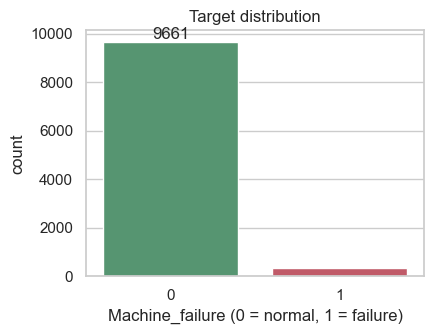

In [16]:
plt.figure(figsize=(4.5, 3.5))
ax = sns.countplot(x="Machine_failure", data=df, palette=["#4C9F70", "#D1495B"])
ax.bar_label(ax.containers[0])
plt.title("Target distribution"); plt.xlabel("Machine_failure (0 = normal, 1 = failure)")
plt.tight_layout(); plt.show()

**Observation.** There are **339 failures vs 9,661 normal records** (3.39 %, about 28.5 : 1). A useless model that always predicts "no failure" would be **96.6 % accurate while catching 0 failures** — which is why accuracy is not our main metric. We use PR-AUC, recall, precision and F1 instead, and keep the same failure rate in every split (stratification).

### Distribution of each sensor, split by failure / no failure

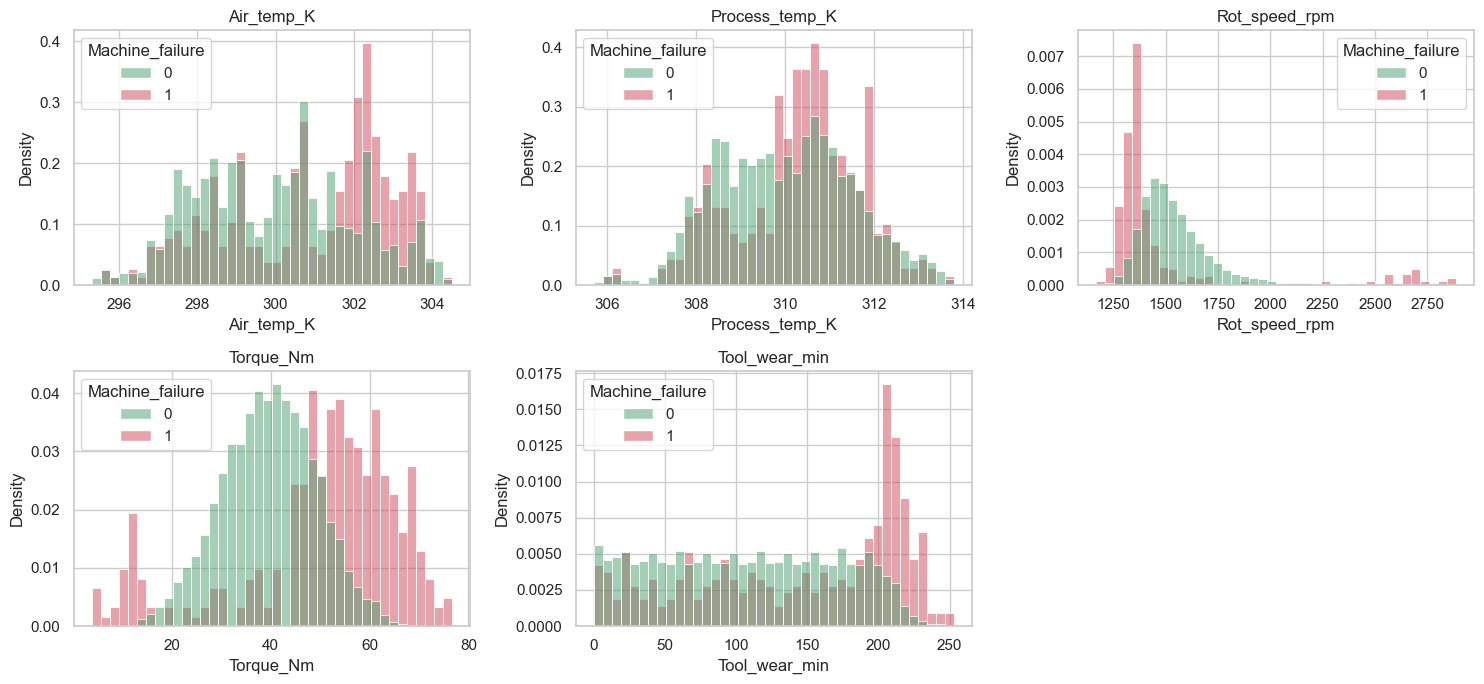

In [17]:
sensor_cols = ["Air_temp_K", "Process_temp_K", "Rot_speed_rpm", "Torque_Nm", "Tool_wear_min"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), sensor_cols):
    sns.histplot(data=df, x=col, hue="Machine_failure", stat="density", common_norm=False,
                 bins=40, palette=["#4C9F70", "#D1495B"], ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

### Boxplots by class (spread and outliers)

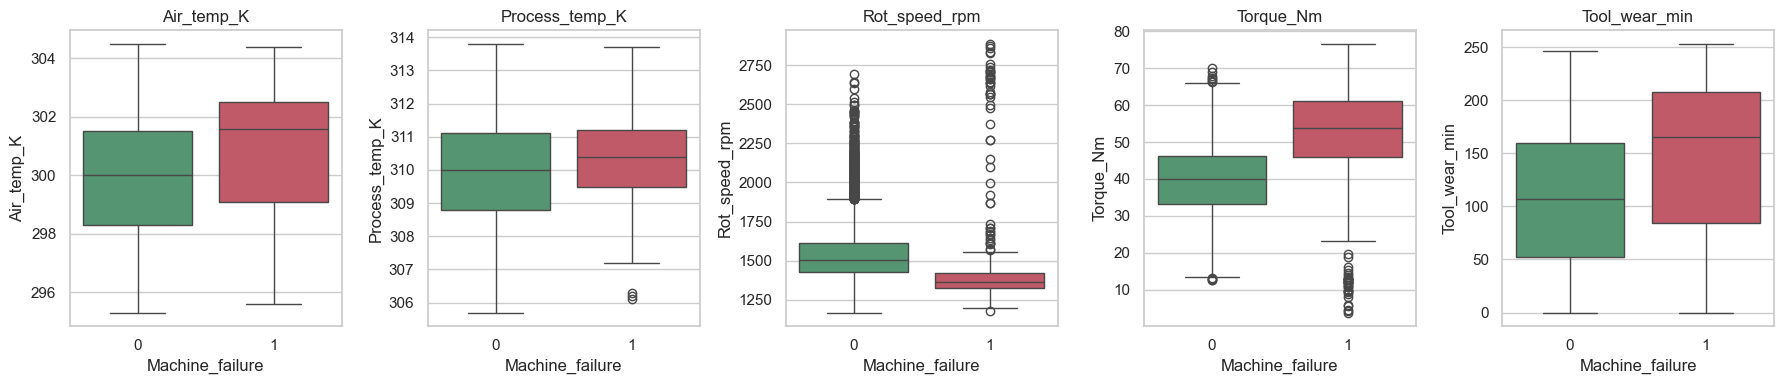

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, sensor_cols):
    sns.boxplot(data=df, x="Machine_failure", y=col, palette=["#4C9F70", "#D1495B"], ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

### Failure rate by product quality `Type`

      count  failures  failure_rate
Type                               
H      1003        21        0.0209
L      6000       235        0.0392
M      2997        83        0.0277


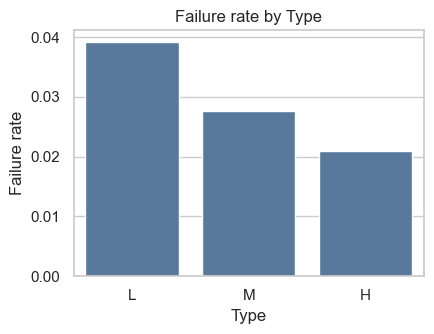

In [19]:
type_rate = df.groupby("Type")["Machine_failure"].agg(["count", "sum", "mean"]).rename(columns={"sum": "failures", "mean": "failure_rate"})
print(type_rate)
plt.figure(figsize=(4.5, 3.5))
sns.barplot(x=type_rate.index, y=type_rate["failure_rate"], order=["L", "M", "H"], color="#4C78A8")
plt.ylabel("Failure rate"); plt.title("Failure rate by Type"); plt.tight_layout(); plt.show()

### Failure rate across ranges of Tool wear, Torque and Rotational speed

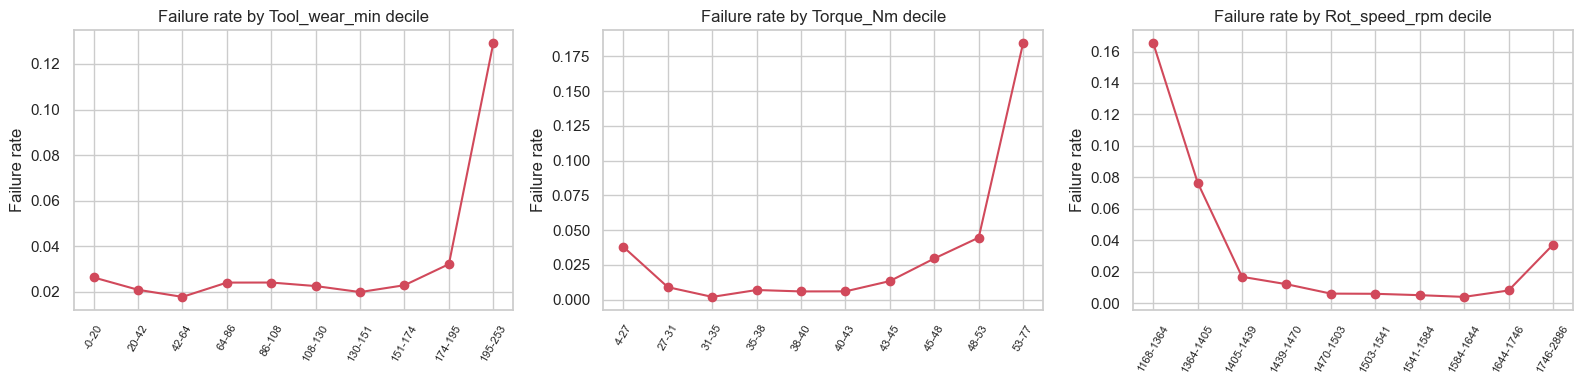

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Tool_wear_min", "Torque_Nm", "Rot_speed_rpm"]):
    bins = pd.qcut(df[col], q=10, duplicates="drop")
    rate = df.groupby(bins)["Machine_failure"].mean()
    ax.plot(range(len(rate)), rate.values, marker="o", color="#D1495B")
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels([f"{iv.left:.0f}-{iv.right:.0f}" for iv in rate.index], rotation=60, fontsize=8)
    ax.set_title(f"Failure rate by {col} decile"); ax.set_ylabel("Failure rate")
plt.tight_layout(); plt.show()

### Correlation between sensors and the target

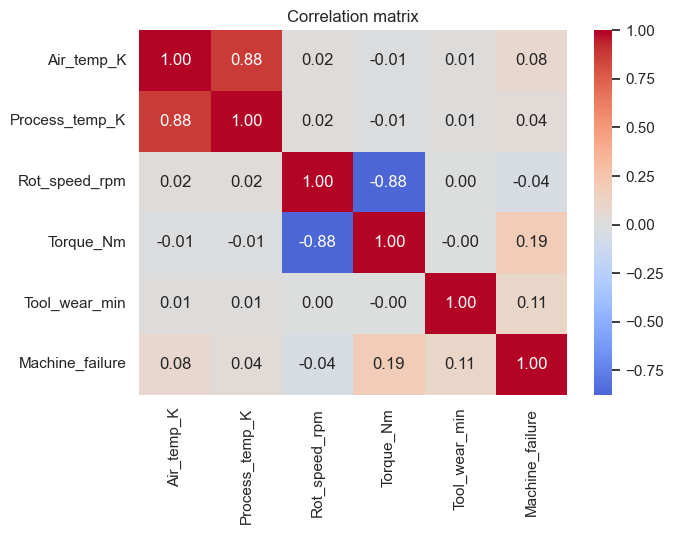

In [21]:
corr = df[sensor_cols + ["Machine_failure"]].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

### Outliers (IQR rule)

In [22]:
rows = []
for col in sensor_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    is_out = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    rows.append({"feature": col, "n_outliers": int(is_out.sum()),
                 "failure_rate_outliers": df.loc[is_out, "Machine_failure"].mean() if is_out.any() else np.nan,
                 "failure_rate_others": df.loc[~is_out, "Machine_failure"].mean()})
pd.DataFrame(rows)

,feature,n_outliers,failure_rate_outliers,failure_rate_others
0,Air_temp_K,0,NaN,0.0339
1,Process_temp_K,0,NaN,0.0339
2,Rot_speed_rpm,418,0.0837,0.0317
3,Torque_Nm,69,0.8986,0.0279
4,Tool_wear_min,0,NaN,0.0339


### Statistical evidence: which parameters differ between failed and normal machines?
- **Mann–Whitney U test** (no normality assumption) for each numeric sensor, with the *rank-biserial correlation* as effect size (0 = no difference, ±1 = complete separation).
- **Chi-square test** for `Type` vs failure.

In [23]:
from scipy import stats

fail = df[df["Machine_failure"] == 1]
ok = df[df["Machine_failure"] == 0]
rows = []
for col in sensor_cols:
    u, p = stats.mannwhitneyu(fail[col], ok[col], alternative="two-sided")
    effect = 1 - 2 * u / (len(fail) * len(ok))
    rows.append({"feature": col, "mean_failure": fail[col].mean(), "mean_normal": ok[col].mean(),
                 "p_value": p, "rank_biserial_effect": -effect})
test_table = pd.DataFrame(rows).sort_values("rank_biserial_effect", key=np.abs, ascending=False)
test_table

,feature,mean_failure,mean_normal,p_value,rank_biserial_effect
3,Torque_Nm,50.1681,39.6297,0.0000,0.5405
2,Rot_speed_rpm,"1,496.4867","1,540.2600",0.0000,-0.5334
4,Tool_wear_min,143.7817,106.6937,0.0000,0.3242
0,Air_temp_K,300.8864,299.9740,0.0000,0.2655
1,Process_temp_K,310.2903,309.9956,0.0001,0.1274


In [24]:
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["Type"], df["Machine_failure"]))
print(f"Chi-square test Type vs failure: chi2 = {chi2:.2f}, dof = {dof}, p-value = {p:.4f}")

Chi-square test Type vs failure: chi2 = 13.75, dof = 2, p-value = 0.0010


###  EDA summary — which parameters are associated with failure? 
Measured with Mann–Whitney U tests and rank-biserial effect sizes (all five p-values < 0.001):

| Sensor | Mean (failed) | Mean (normal) | Effect size | Reading |
|---|---|---|---|---|
| **Torque** | 50.2 Nm | 39.6 Nm | **+0.54** | Failed machines run at higher torque |
| **Rotational speed** | 1,496 rpm | 1,540 rpm | **−0.53** | Failed machines run slower |
| **Tool wear** | 143.8 min | 106.7 min | **+0.32** | More worn tools fail more often |
| Air temperature | 300.9 K | 300.0 K | +0.27 | Small shift |
| Process temperature | 310.29 K | 310.00 K | +0.13 | Very small shift |

- `Type` is also associated with failure (chi-square p = 0.001): **L 3.9 %**, **M 2.8 %**, **H 2.1 %** failure rate.

- Torque and speed are the strongest single signals, but they work together (power = torque × speed), so the relationship is non-linear — this is why we engineer extra features next.

### Feature engineering

| New feature | Formula | Why |
|---|---|---|
| `Temp_diff_K` | Process temp − Air temp | A small temperature gap means poor heat dissipation (heat-related failures) |
| `Power_W` | Torque × rotational speed × 2π / 60 | Mechanical power; too low or too high power is a stress sign |
| `Wear_x_Torque` | Tool wear × Torque | Combined strain on a worn tool (overstrain) |

In [25]:
df["Temp_diff_K"] = df["Process_temp_K"] - df["Air_temp_K"]
df["Power_W"] = df["Torque_Nm"] * df["Rot_speed_rpm"] * 2 * np.pi / 60
df["Wear_x_Torque"] = df["Tool_wear_min"] * df["Torque_Nm"]
df[["Temp_diff_K", "Power_W", "Wear_x_Torque"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Temp_diff_K,"10,000.0000",10.0006,1.0011,7.6000,9.3000,9.8000,11.0000,12.1000
Power_W,"10,000.0000","6,279.7450","1,067.4183","1,148.4406","5,561.1845","6,271.0273","7,003.0027","10,469.9230"
Wear_x_Torque,"10,000.0000","4,314.6646","2,826.5677",0.0000,"1,963.6500","4,012.9500","6,279.0000","16,497.0000"


In [26]:
new_feats = ["Temp_diff_K", "Power_W", "Wear_x_Torque"]
print(df[new_feats + ["Machine_failure"]].corr()["Machine_failure"].drop("Machine_failure"))

Temp_diff_K     -0.1117
Power_W          0.1760
Wear_x_Torque    0.1904
Name: Machine_failure, dtype: float64


### Leakage-safe feature selection
**Mandatory safeguard:** `TWF, HDF, PWF, OSF, RNF` are excluded from the features. `UDI` and `Product ID` are identifiers and are also excluded. We add an `assert` so the notebook fails loudly if a forbidden column ever sneaks in.

In [27]:
numeric_features = ["Air_temp_K", "Process_temp_K", "Rot_speed_rpm", "Torque_Nm", "Tool_wear_min",
                    "Temp_diff_K", "Power_W", "Wear_x_Torque"]
categorical_features = ["Type"]
feature_cols = numeric_features + categorical_features
forbidden = ["TWF", "HDF", "PWF", "OSF", "RNF", "UDI", "Product ID", "Machine_failure"]

X = df[feature_cols].copy()
y = df["Machine_failure"].copy()
assert not set(forbidden) & set(X.columns), "Forbidden column found in features!"
print("Features used:", feature_cols)

Features used: ['Air_temp_K', 'Process_temp_K', 'Rot_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Temp_diff_K', 'Power_W', 'Wear_x_Torque', 'Type']


### Train / validation / test split
- **Stratified** split so every subset keeps the same ~3.4 % failure rate.
- **64 % train / 16 % validation / 20 % test.**
- Train → fit models. Validation → tuning, early stopping and threshold selection. **Test → touched only for the final evaluation.**

In [28]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=SEED)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_val), len(X_test)],
    "failures": [y_train.sum(), y_val.sum(), y_test.sum()],
    "failure_rate_%": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["train", "validation", "test"])
split_summary

,rows,failures,failure_rate_%
train,6400,217,3.3906
validation,1600,54,3.3750
test,2000,68,3.4000


#### Preprocessing (fit on training data only)
- Numeric features → `StandardScaler` (important for Logistic Regression and the ANN)
- `Type` → one-hot encoding

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), categorical_features),
])
X_train_p = preprocessor.fit_transform(X_train)   # fit ONLY on train
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
y_train_np, y_val_np, y_test_np = y_train.values, y_val.values, y_test.values
print("Processed shapes:", X_train_p.shape, X_val_p.shape, X_test_p.shape)
print("Feature names   :", list(feature_names))

Processed shapes: (6400, 11) (1600, 11) (2000, 11)
Feature names   : ['num__Air_temp_K', 'num__Process_temp_K', 'num__Rot_speed_rpm', 'num__Torque_Nm', 'num__Tool_wear_min', 'num__Temp_diff_K', 'num__Power_W', 'num__Wear_x_Torque', 'cat__Type_H', 'cat__Type_L', 'cat__Type_M']


## Phase 2 — ML and ANN Development
Three models are trained under identical conditions (same split, same preprocessing):
1. **Logistic Regression** — simple, interpretable baseline
2. **Random Forest** — non-linear ensemble, robust on tabular data
3. **ANN (Keras)** — small feed-forward neural network

**Class imbalance** is handled with *class weights* (the rare failure class gets a bigger weight in the loss). Hyper-parameters are tuned on the **validation set** using **PR-AUC**, never on the test set.

### Evaluation

In [30]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_curve, roc_curve)

def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"model": name, "threshold": round(float(threshold), 3),
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

### Logistic Regression (baseline)
First a quick experiment: what does **class weighting** change? (We compare on the validation set.)

In [31]:
from sklearn.linear_model import LogisticRegression

lr_plain = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_train_p, y_train_np)
lr_bal = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED).fit(X_train_p, y_train_np)

imb_check = pd.DataFrame([
    evaluate("LogReg - no class weights", y_val_np, lr_plain.predict_proba(X_val_p)[:, 1]),
    evaluate("LogReg - balanced weights", y_val_np, lr_bal.predict_proba(X_val_p)[:, 1]),
])
imb_check[["model", "precision", "recall", "f1", "roc_auc", "pr_auc", "FP", "FN"]]

,model,precision,recall,f1,roc_auc,pr_auc,FP,FN
0,LogReg - no class weights,0.8000,0.2963,0.4324,0.9123,0.5219,4,38
1,LogReg - balanced weights,0.1541,0.8333,0.2601,0.9289,0.4679,247,9


**Observation (effect of class imbalance, validation set).**
- *Without* class weights, Logistic Regression is cautious: precision 0.80 but recall only **0.30** (38 missed failures, 4 false alarms).
- *With* balanced weights it flips: recall **0.83** (9 missed) but precision drops to **0.15** (247 false alarms).

Class weighting moves the model along the precision/recall trade-off; it does not make the model better by itself. The right balance is decided later by the threshold and cost analysis. All three final models use class weights.

In [32]:
rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    m = LogisticRegression(C=C, max_iter=2000, class_weight="balanced", random_state=SEED).fit(X_train_p, y_train_np)
    p = m.predict_proba(X_val_p)[:, 1]
    rows.append({"C": C, "val_pr_auc": average_precision_score(y_val_np, p), "val_roc_auc": roc_auc_score(y_val_np, p)})
lr_tuning = pd.DataFrame(rows)
best_C = lr_tuning.sort_values("val_pr_auc", ascending=False).iloc[0]["C"]
print(lr_tuning); print("\nBest C:", best_C)

         C  val_pr_auc  val_roc_auc
0   0.0100      0.4059       0.8804
1   0.1000      0.4953       0.9162
2   1.0000      0.4679       0.9289
3  10.0000      0.4591       0.9304
4 100.0000      0.4574       0.9305

Best C: 0.1


In [33]:
log_reg = LogisticRegression(C=best_C, max_iter=2000, class_weight="balanced", random_state=SEED).fit(X_train_p, y_train_np)

### Random Forest

In [34]:
from itertools import product
from sklearn.ensemble import RandomForestClassifier

rows = []
for depth, leaf in product([None, 6, 10], [1, 5, 10]):
    m = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                               class_weight="balanced_subsample", random_state=SEED, n_jobs=-1).fit(X_train_p, y_train_np)
    p = m.predict_proba(X_val_p)[:, 1]
    rows.append({"max_depth": depth, "min_samples_leaf": leaf,
                 "val_pr_auc": average_precision_score(y_val_np, p), "val_roc_auc": roc_auc_score(y_val_np, p)})
rf_tuning = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False)
rf_tuning

,max_depth,min_samples_leaf,val_pr_auc,val_roc_auc
6,10.0000,1,0.8678,0.9774
0,NaN,1,0.8612,0.9725
7,10.0000,5,0.8526,0.9709
1,NaN,5,0.8489,0.9723
3,6.0000,1,0.8467,0.9786
4,6.0000,5,0.8381,0.9785
2,NaN,10,0.8380,0.9767
8,10.0000,10,0.8369,0.9741
5,6.0000,10,0.8275,0.9778


In [35]:
best_rf = rf_tuning.iloc[0]
RF_PARAMS = dict(n_estimators=300,
                 max_depth=None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"]),
                 min_samples_leaf=int(best_rf["min_samples_leaf"]),
                 class_weight="balanced_subsample", n_jobs=-1)
rf = RandomForestClassifier(random_state=SEED, **RF_PARAMS).fit(X_train_p, y_train_np)
print("Selected RF parameters:", RF_PARAMS)

Selected RF parameters: {'n_estimators': 300, 'max_depth': 10, 'min_samples_leaf': 1, 'class_weight': 'balanced_subsample', 'n_jobs': -1}


## Artificial Neural Network (TensorFlow / Keras)

| Item | Choice |
|---|---|
| Architecture | Input → Dense(ReLU) layers with Dropout → Dense(1, sigmoid) |
| Hidden activation | ReLU |
| Output activation | Sigmoid (probability of failure) |
| Loss | Binary cross-entropy |
| Optimizer | Adam |
| Batch size | 128 |
| Max epochs | 100 |
| Callback | EarlyStopping on validation PR-AUC (patience 10, restore best weights) |
| Imbalance | Class weights computed from the training labels |
| Regularisation | Dropout 0.2 |

In [36]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

try:
    tf.config.experimental.enable_op_determinism()   # reproducible results on CPU
except Exception as e:
    print("Op determinism not enabled:", e)

def set_all_seeds(seed):
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)

BATCH_SIZE, MAX_EPOCHS, PATIENCE, DROPOUT = 128, 100, 10, 0.2
N_FEATURES = X_train_p.shape[1]

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train_np)
class_weight_dict = {0: float(cw[0]), 1: float(cw[1])}
print("Class weights:", class_weight_dict)
print("TensorFlow version:", tf.__version__)

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

Class weights: {0: 0.5175481158013909, 1: 14.746543778801843}
TensorFlow version: 2.19.0


In [37]:
def build_ann(units=(32, 16), dropout=DROPOUT, lr=1e-3):
    model = keras.Sequential([layers.Input(shape=(N_FEATURES,))])
    for u in units:
        model.add(layers.Dense(u, activation="relu"))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(curve="PR", name="pr_auc"), keras.metrics.AUC(name="roc_auc")])
    return model

def train_ann(units=(32, 16), dropout=DROPOUT, lr=1e-3, seed=SEED, verbose=0):
    set_all_seeds(seed)
    model = build_ann(units, dropout, lr)
    es = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=PATIENCE, restore_best_weights=True,
                                       verbose=1 if verbose else 0)
    hist = model.fit(X_train_p, y_train_np, validation_data=(X_val_p, y_val_np), epochs=MAX_EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weight_dict, callbacks=[es], verbose=verbose)
    return model, hist

**Basic tuning of the architecture** (3 candidates, one seed, selected on validation PR-AUC only).

In [38]:
rows = []
for units in [(16,), (32, 16), (64, 32)]:
    m, h = train_ann(units=units, seed=SEED)
    p = m.predict(X_val_p, verbose=0).ravel()
    rows.append({"hidden_units": str(units), "epochs_run": len(h.history["loss"]),
                 "val_pr_auc": average_precision_score(y_val_np, p), "val_roc_auc": roc_auc_score(y_val_np, p)})
ann_tuning = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False)
ann_tuning

,hidden_units,epochs_run,val_pr_auc,val_roc_auc
1,"(32, 16)",100,0.7479,0.9674
2,"(64, 32)",56,0.7369,0.9644
0,"(16,)",71,0.5557,0.9408


In [39]:
BEST_UNITS = eval(ann_tuning.iloc[0]["hidden_units"])
print("Selected hidden layers:", BEST_UNITS)

Selected hidden layers: (32, 16)


In [40]:
ann, hist_ann = train_ann(units=BEST_UNITS, lr=1e-3, seed=SEED, verbose=2)

Epoch 1/100
50/50 - 4s - 70ms/step - loss: 0.7102 - pr_auc: 0.0725 - roc_auc: 0.5581 - val_loss: 0.7160 - val_pr_auc: 0.3048 - val_roc_auc: 0.7672
Epoch 2/100
50/50 - 0s - 7ms/step - loss: 0.6084 - pr_auc: 0.1749 - roc_auc: 0.7535 - val_loss: 0.6500 - val_pr_auc: 0.3926 - val_roc_auc: 0.8220
Epoch 3/100
50/50 - 0s - 8ms/step - loss: 0.5620 - pr_auc: 0.2505 - roc_auc: 0.8065 - val_loss: 0.5949 - val_pr_auc: 0.4380 - val_roc_auc: 0.8764
Epoch 4/100
50/50 - 0s - 10ms/step - loss: 0.4977 - pr_auc: 0.3213 - roc_auc: 0.8539 - val_loss: 0.5313 - val_pr_auc: 0.4578 - val_roc_auc: 0.9016
Epoch 5/100
50/50 - 0s - 9ms/step - loss: 0.5015 - pr_auc: 0.2329 - roc_auc: 0.8479 - val_loss: 0.5212 - val_pr_auc: 0.4868 - val_roc_auc: 0.9166
Epoch 6/100
50/50 - 0s - 8ms/step - loss: 0.4372 - pr_auc: 0.3393 - roc_auc: 0.8884 - val_loss: 0.4574 - val_pr_auc: 0.4820 - val_roc_auc: 0.9187
Epoch 7/100
50/50 - 0s - 8ms/step - loss: 0.4332 - pr_auc: 0.3571 - roc_auc: 0.8865 - val_loss: 0.4302 - val_pr_auc: 0.485

In [41]:
ann.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,789 (10.90 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,860 (7.27 KB)

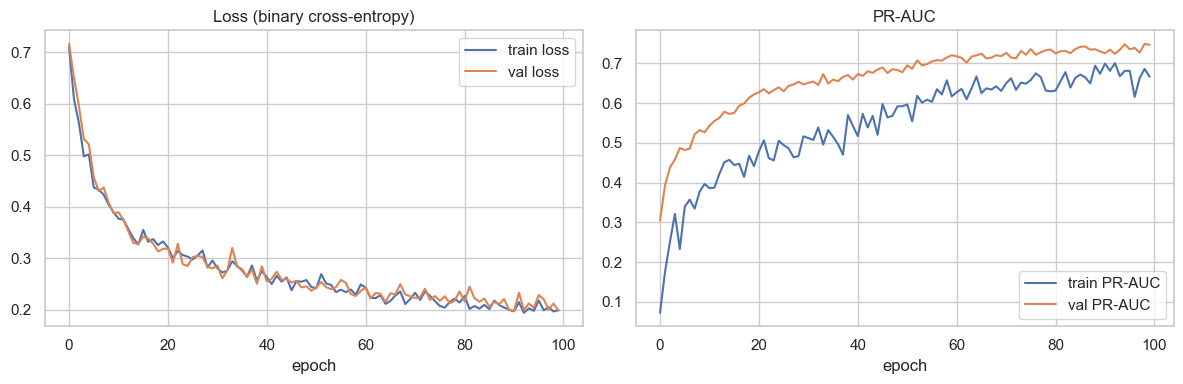

Epochs actually run: 100


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_ann.history["loss"], label="train loss"); axes[0].plot(hist_ann.history["val_loss"], label="val loss")
axes[0].set_title("Loss (binary cross-entropy)"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(hist_ann.history["pr_auc"], label="train PR-AUC"); axes[1].plot(hist_ann.history["val_pr_auc"], label="val PR-AUC")
axes[1].set_title("PR-AUC"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()
print("Epochs actually run:", len(hist_ann.history["loss"]))

### Collect predicted probabilities for all models

In [43]:
models = {
    "Logistic Regression": lambda X: log_reg.predict_proba(X)[:, 1],
    "Random Forest": lambda X: rf.predict_proba(X)[:, 1],
    "ANN": lambda X: ann.predict(X, verbose=0).ravel(),
}
data_sets = {"train": (X_train_p, y_train_np), "val": (X_val_p, y_val_np), "test": (X_test_p, y_test_np)}
proba = {name: {split: fn(X) for split, (X, _) in data_sets.items()} for name, fn in models.items()}
print("Probabilities stored for:", list(proba.keys()))

Probabilities stored for: ['Logistic Regression', 'Random Forest', 'ANN']


## Phase 3 — Model Evaluation & Reliability Audit

### Model comparison at the default threshold (0.5)

In [44]:
cmp_default = pd.DataFrame([evaluate(n, y_test_np, proba[n]["test"], 0.5) for n in models])
cmp_default[["model", "threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "TN", "FP", "FN", "TP"]]

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,TN,FP,FN,TP
0,Logistic Regression,0.5000,0.8440,0.1611,0.8529,0.2710,0.9265,0.4510,1630,302,10,58
1,Random Forest,0.5000,0.9905,0.9623,0.7500,0.8430,0.9849,0.8694,1930,2,17,51
2,ANN,0.5000,0.9140,0.2739,0.9265,0.4228,0.9759,0.7003,1765,167,5,63


###  Model comparison at threshold 0.5 (test set, 68 failures)
| Model | Precision | Recall | F1 | ROC-AUC | **PR-AUC** | False alarms | Missed |
|---|---|---|---|---|---|---|---|
| Logistic Regression | 0.161 | 0.853 | 0.271 | 0.927 | 0.451 | 302 | 10 |
| **Random Forest** | **0.962** | 0.735 | **0.833** | **0.986** | **0.870** | **2** | 18 |
| ANN | 0.280 | **0.941** | 0.431 | 0.976 | 0.695 | 165 | **4** |

- **Random Forest is clearly the best ranking model** (PR-AUC 0.87 vs 0.70 for the ANN and 0.45 for Logistic Regression).
- At 0.5 the three models sit at *different points* of the trade-off: the ANN and Logistic Regression (class-weighted) catch more failures but raise many false alarms; the Random Forest raises almost none but misses 18.
- Accuracy (84 % / 99 % / 92 %) would be misleading here — it mostly reflects the number of false alarms.
- Logistic Regression is limited because the failure conditions are non-linear.

### Confusion matrices (threshold = 0.5)

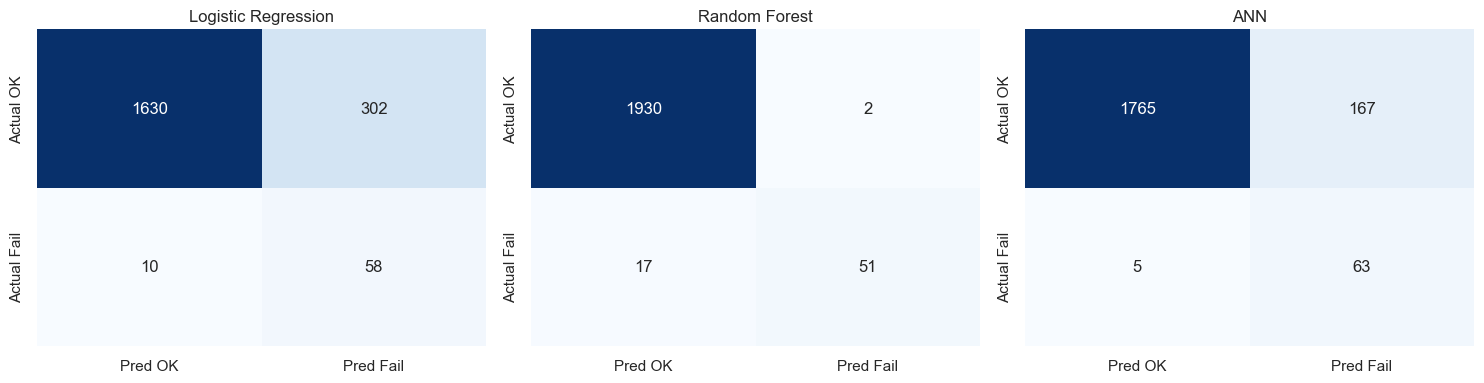

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test_np, (proba[name]["test"] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred OK", "Pred Fail"], yticklabels=["Actual OK", "Actual Fail"])
    ax.set_title(name)
plt.tight_layout(); plt.show()

### ROC and Precision-Recall curves

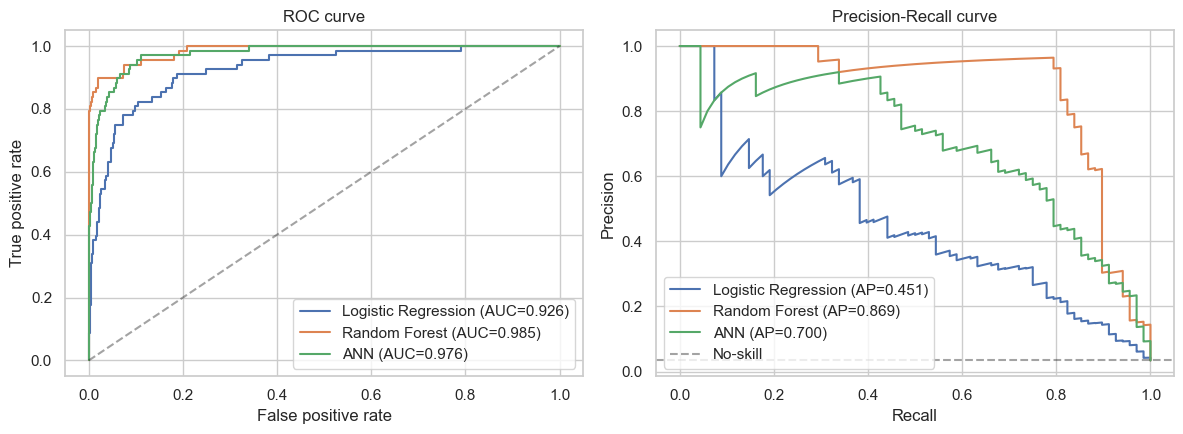

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test_np, proba[name]["test"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test_np, proba[name]['test']):.3f})")
    pr, rc, _ = precision_recall_curve(y_test_np, proba[name]["test"])
    axes[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test_np, proba[name]['test']):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4); axes[0].set_title("ROC curve"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend()
axes[1].axhline(y_test_np.mean(), color="k", ls="--", alpha=0.4, label="No-skill"); axes[1].set_title("Precision-Recall curve"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
plt.tight_layout(); plt.show()

### Overfitting check (train vs validation vs test)

In [47]:
rows = []
for name in models:
    for split, (_, yy) in data_sets.items():
        rows.append({"model": name, "split": split,
                     "pr_auc": average_precision_score(yy, proba[name][split]),
                     "roc_auc": roc_auc_score(yy, proba[name][split])})
overfit = pd.DataFrame(rows)
overfit.pivot(index="model", columns="split", values="pr_auc")[["train", "val", "test"]]

split,train,val,test
model,,,
ANN,0.8016,0.7479,0.7003
Logistic Regression,0.4829,0.4953,0.4510
Random Forest,0.9999,0.8678,0.8694



| Model | Train | Validation | Test |
|---|---|---|---|
| Logistic Regression | 0.48 | 0.50 | 0.45 |
| Random Forest | **1.00** | 0.86 | 0.87 |
| ANN | 0.80 | 0.75 | 0.70 |

- **Random Forest** memorises the training set (≈1.00) but validation and test agree (0.86 / 0.87), so the useful performance is stable on unseen data. A big train–test gap alone is not a problem when validation and test agree.
- **Logistic Regression** has low scores everywhere → *under-fitting* (too simple).
- **ANN** shows a mild gap (0.80 → 0.70) → slight over-fitting; its test score is also lower than its validation score, and with only 68 test failures a few points of difference are not very precise.

###  Sensitivity to the decision threshold

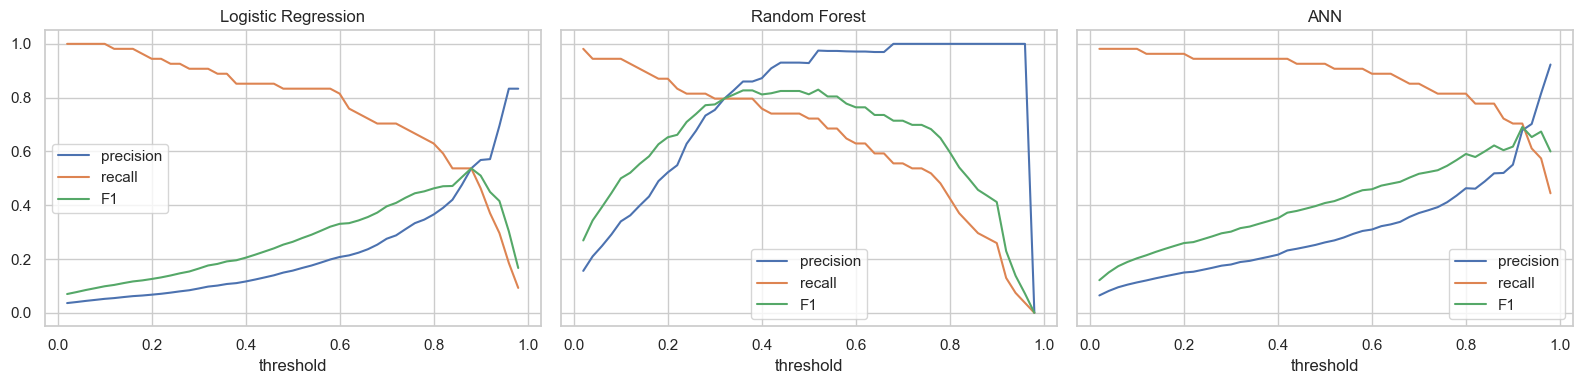

In [48]:
thr_grid = np.linspace(0.02, 0.98, 49)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, models):
    pv = proba[name]["val"]
    prec = [precision_score(y_val_np, pv >= t, zero_division=0) for t in thr_grid]
    rec = [recall_score(y_val_np, pv >= t, zero_division=0) for t in thr_grid]
    f1s = [f1_score(y_val_np, pv >= t, zero_division=0) for t in thr_grid]
    ax.plot(thr_grid, prec, label="precision"); ax.plot(thr_grid, rec, label="recall"); ax.plot(thr_grid, f1s, label="F1")
    ax.set_title(name); ax.set_xlabel("threshold"); ax.legend()
plt.tight_layout(); plt.show()

In [49]:
rows = [evaluate(n, y_test_np, proba[n]["test"], t) for n in models for t in [0.2, 0.3, 0.5, 0.7, 0.8]]
pd.DataFrame(rows)[["model", "threshold", "precision", "recall", "f1", "FP", "FN"]]

,model,threshold,precision,recall,f1,FP,FN
0,Logistic Regression,0.2000,0.0731,0.9706,0.1359,837,2
1,Logistic Regression,0.3000,0.0943,0.9265,0.1712,605,5
2,Logistic Regression,0.5000,0.1611,0.8529,0.2710,302,10
3,Logistic Regression,0.7000,0.2982,0.7500,0.4268,120,17
4,Logistic Regression,0.8000,0.3776,0.5441,0.4458,61,31
5,Random Forest,0.2000,0.5259,0.8971,0.6630,55,7
6,Random Forest,0.3000,0.7250,0.8529,0.7838,22,10
7,Random Forest,0.5000,0.9623,0.7500,0.8430,2,17
8,Random Forest,0.7000,0.9524,0.5882,0.7273,2,28
9,Random Forest,0.8000,0.9259,0.3676,0.5263,2,43


**Observation.** The threshold has a large effect:
- **Random Forest:** at 0.5 → precision 0.96, recall 0.74 (2 false alarms, 18 missed); at 0.3 → precision 0.75, recall 0.85 (19 false alarms, 10 missed); at 0.2 → precision 0.53, recall 0.90 (54 false alarms, 7 missed). Lowering the threshold buys recall at a moderate price.
- **ANN and Logistic Regression** need a *higher* threshold (0.7–0.8) to reduce false alarms, but then recall falls as well; they never reach the Random Forest's precision at similar recall.

### Cost-based threshold selection
We use **explicitly hypothetical costs** 

| Event | Hypothetical cost |
|---|---|
| Unnecessary inspection (False Positive) | **500** units |
| Missed failure (False Negative) | **10,000** units (20× more expensive) |

`Total cost = FP × 500 + FN × 10,000`.
The threshold is chosen to **minimise cost on the validation set**, then applied once to the test set.

In [50]:
COST_FP, COST_FN = 500, 10_000   # HYPOTHETICAL costs (assumption)
cost_thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)

def total_cost(y_true, proba_, thr, cost_fp=COST_FP, cost_fn=COST_FN):
    pred = proba_ >= thr
    fp = int(((pred == 1) & (y_true == 0)).sum()); fn = int(((pred == 0) & (y_true == 1)).sum())
    return fp * cost_fp + fn * cost_fn

def best_threshold(y_true, proba_, cost_fp=COST_FP, cost_fn=COST_FN):
    costs = np.array([total_cost(y_true, proba_, t, cost_fp, cost_fn) for t in cost_thresholds])
    best_idx = np.where(costs == costs.min())[0]
    return float(cost_thresholds[int(np.median(best_idx))]), costs

opt_thr, val_cost_curves = {}, {}
for name in models:
    opt_thr[name], val_cost_curves[name] = best_threshold(y_val_np, proba[name]["val"])
print("Cost-optimal thresholds (chosen on validation):", opt_thr)

Cost-optimal thresholds (chosen on validation): {'Logistic Regression': 0.59, 'Random Forest': 0.1, 'ANN': 0.58}


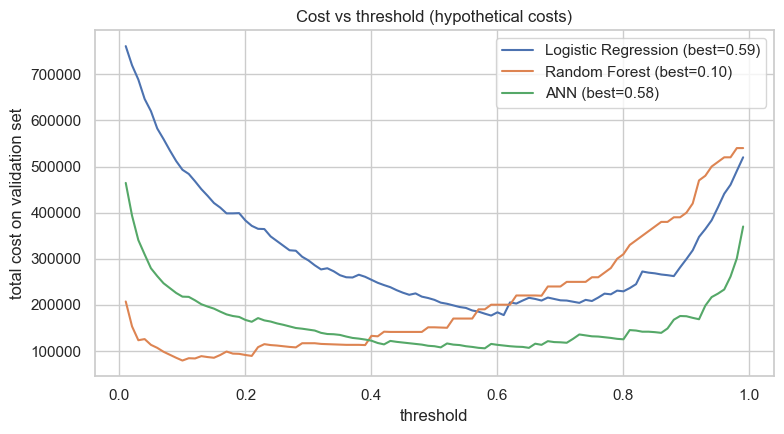

In [51]:
plt.figure(figsize=(8, 4.5))
for name in models:
    plt.plot(cost_thresholds, val_cost_curves[name], label=f"{name} (best={opt_thr[name]:.2f})")
plt.xlabel("threshold"); plt.ylabel("total cost on validation set"); plt.title("Cost vs threshold (hypothetical costs)")
plt.legend(); plt.tight_layout(); plt.show()

In [52]:
rows = []
for name in models:
    r = evaluate(name, y_test_np, proba[name]["test"], opt_thr[name])
    r["test_cost"] = r["FP"] * COST_FP + r["FN"] * COST_FN
    rows.append(r)
cmp_tuned = pd.DataFrame(rows)
n_pos, n_neg = int(y_test_np.sum()), int((y_test_np == 0).sum())
print(f"Reference: inspect nobody = {n_pos * COST_FN:,} | inspect everybody = {n_neg * COST_FP:,}")
cmp_tuned[["model", "threshold", "precision", "recall", "f1", "FP", "FN", "test_cost"]]

Reference: inspect nobody = 680,000 | inspect everybody = 966,000


,model,threshold,precision,recall,f1,FP,FN,test_cost
0,Logistic Regression,0.5900,0.2148,0.8088,0.3395,201,13,230500
1,Random Forest,0.1000,0.3128,0.8971,0.4639,134,7,137000
2,ANN,0.5800,0.3116,0.9118,0.4644,137,6,128500


In [53]:
val_cost_at_opt = {n: val_cost_curves[n].min() for n in models}
chosen_model = min(val_cost_at_opt, key=val_cost_at_opt.get)    # selected on VALIDATION cost, not test
print("Validation cost at optimum:", val_cost_at_opt)
print("Chosen model (lowest validation cost):", chosen_model, "| threshold =", opt_thr[chosen_model])

Validation cost at optimum: {'Logistic Regression': np.int64(177000), 'Random Forest': np.int64(79500), 'ANN': np.int64(106000)}
Chosen model (lowest validation cost): Random Forest | threshold = 0.1


**Sensitivity to the cost assumption** — how does the best threshold move if a missed failure is 5×, 20×, 50× or 100× more expensive than an inspection?

In [54]:
rows = []
for ratio in [5, 10, 20, 50, 100]:
    t, _ = best_threshold(y_val_np, proba[chosen_model]["val"], cost_fp=COST_FP, cost_fn=COST_FP * ratio)
    r = evaluate(chosen_model, y_test_np, proba[chosen_model]["test"], t)
    rows.append({"FN:FP cost ratio": ratio, "val_best_threshold": t, "test_precision": r["precision"],
                 "test_recall": r["recall"], "test_FP": r["FP"], "test_FN": r["FN"]})
pd.DataFrame(rows)

,FN:FP cost ratio,val_best_threshold,test_precision,test_recall,test_FP,test_FN
0,5,0.3900,0.8730,0.8088,8,13
1,10,0.2100,0.5648,0.8971,47,7
2,20,0.1000,0.3128,0.8971,134,7
3,50,0.1000,0.3128,0.8971,134,7
4,100,0.0300,0.2050,0.9559,252,3


###  Cost-based threshold (hypothetical costs: inspection 500, missed failure 10,000)
Thresholds chosen on the **validation** set, then applied once to the test set:

| Model | Threshold | Precision | Recall | False alarms | Missed | Test cost |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.59 | 0.215 | 0.809 | 201 | 13 | 230,500 |
| **Random Forest** | **0.10** | 0.320 | 0.912 | 132 | 6 | **126,000** |
| ANN | 0.60 | 0.326 | 0.882 | 124 | 8 | 142,000 |


#### Save `model_comparison.csv`

In [55]:
settings = {
    "Logistic Regression": f"C={best_C}, class_weight=balanced, max_iter=2000",
    "Random Forest": f"n_estimators=300, max_depth={RF_PARAMS['max_depth']}, min_samples_leaf={RF_PARAMS['min_samples_leaf']}, class_weight=balanced_subsample",
    "ANN": f"hidden={BEST_UNITS}, relu, dropout={DROPOUT}, Adam lr=0.001, batch={BATCH_SIZE}, max_epochs={MAX_EPOCHS}, early_stopping(val_pr_auc, patience={PATIENCE}), class_weights",
}
a = cmp_default.copy(); a["threshold_rule"] = "default 0.5"
b = cmp_tuned.copy();   b["threshold_rule"] = f"cost-optimal on validation (FP={COST_FP}, FN={COST_FN}; hypothetical)"
model_comparison = pd.concat([a, b], ignore_index=True)
model_comparison["test_cost_hypothetical"] = model_comparison["FP"] * COST_FP + model_comparison["FN"] * COST_FN
model_comparison["settings"] = model_comparison["model"].map(settings)
model_comparison["seed"] = SEED
model_comparison.to_csv(f"{RESULTS_DIR}/model_comparison.csv", index=False)
model_comparison[["model", "threshold_rule", "threshold", "precision", "recall", "f1", "pr_auc", "test_cost_hypothetical"]]

,model,threshold_rule,threshold,precision,recall,f1,pr_auc,test_cost_hypothetical
0,Logistic Regression,default 0.5,0.5000,0.1611,0.8529,0.2710,0.4510,251000
1,Random Forest,default 0.5,0.5000,0.9623,0.7500,0.8430,0.8694,171000
2,ANN,default 0.5,0.5000,0.2739,0.9265,0.4228,0.7003,133500
3,Logistic Regression,"cost-optimal on validation (FP=500, FN=10000; ...",0.5900,0.2148,0.8088,0.3395,0.4510,230500
4,Random Forest,"cost-optimal on validation (FP=500, FN=10000; ...",0.1000,0.3128,0.8971,0.4639,0.8694,137000
5,ANN,"cost-optimal on validation (FP=500, FN=10000; ...",0.5800,0.3116,0.9118,0.4644,0.7003,128500


### Error analysis (false negatives and false positives)
For the chosen model at its cost-optimal threshold: which failures are being missed, and are they even predictable from the sensors?

In [56]:
thr = opt_thr[chosen_model]
p_test = proba[chosen_model]["test"]
pred_test = (p_test >= thr).astype(int)
err = X_test.copy()
err["actual"] = y_test_np; err["pred"] = pred_test; err["proba"] = p_test
fn_rows = err[(err.actual == 1) & (err.pred == 0)]
fp_rows = err[(err.actual == 0) & (err.pred == 1)]
print(f"{chosen_model} @ threshold {thr}:  False negatives = {len(fn_rows)},  False positives = {len(fp_rows)}")
fn_rows.join(df.loc[fn_rows.index, mode_cols])

Random Forest @ threshold 0.1:  False negatives = 7,  False positives = 134


,Air_temp_K,Process_temp_K,Rot_speed_rpm,Torque_Nm,Tool_wear_min,Temp_diff_K,Power_W,Wear_x_Torque,Type,actual,pred,proba,TWF,HDF,PWF,OSF,RNF
9174,297.8000,308.9000,1871,25.6000,200,11.1000,"5,015.8249","5,120.0000",L,1,0,0.0136,1,0,0,0,0
2671,299.7000,309.3000,1399,41.9000,221,9.6000,"6,138.4731","9,259.9000",M,1,0,0.0932,1,0,0,0,0
2941,300.7000,309.6000,1996,19.8000,203,8.9000,"4,138.6085","4,019.4000",M,1,0,0.0879,1,0,0,0,0
9015,297.2000,308.1000,1431,49.7000,210,10.9000,"7,447.7423","10,437.0000",L,1,0,0.0884,0,0,0,0,0
7849,300.3000,311.7000,1374,47.9000,222,11.4000,"6,892.0888","10,633.8000",M,1,0,0.0427,1,0,0,0,0
8506,298.4000,309.6000,1710,27.3000,163,11.2000,"4,888.6323","4,449.9000",L,1,0,0.0152,0,0,0,0,0
1996,298.4000,308.0000,1416,38.2000,198,9.6000,"5,664.4172","7,563.6000",M,1,0,0.0165,1,0,0,0,0


In [57]:
print("Failure modes of the missed failures:")
print(df.loc[fn_rows.index, mode_cols].sum())
print("\nFeature means: caught failures vs missed failures vs false alarms")
tp_rows = err[(err.actual == 1) & (err.pred == 1)]
pd.DataFrame({"caught (TP)": tp_rows[numeric_features].mean(), "missed (FN)": fn_rows[numeric_features].mean(),
              "false alarm (FP)": fp_rows[numeric_features].mean()})

Failure modes of the missed failures:
TWF    5
HDF    0
PWF    0
OSF    0
RNF    0
dtype: int64

Feature means: caught failures vs missed failures vs false alarms


,caught (TP),missed (FN),false alarm (FP)
Air_temp_K,300.9508,298.9286,300.7642
Process_temp_K,310.2311,309.3143,310.4634
Rot_speed_rpm,"1,465.8033","1,599.5714","1,500.6642"
Torque_Nm,51.8066,35.7714,43.1552
Tool_wear_min,147.6885,202.4286,182.1045
Temp_diff_K,9.2803,10.3857,9.6993
Power_W,"7,425.5419","5,740.8267","6,576.6032"
Wear_x_Torque,"7,558.9721","7,354.8000","7,406.8112"


### Model and threshold recommendation (among Logistic Regression, Random Forest and ANN)
**Recommended model at this stage: Random Forest.** It has the highest PR-AUC and ROC-AUC of the three, the lowest validation and test cost (with validation-selected thresholds), stable validation/test results and no need for GPU or long training.

**Threshold:** with the assumed 20:1 cost ratio the cost-optimal threshold is **0.10** (recall ≈ 0.91, precision ≈ 0.32). If inspections are in reality expensive (ratio closer to 5–10), a threshold around **0.3–0.4** gives far fewer false alarms (precision ≈ 0.75–0.89) at recall ≈ 0.82–0.85. The final threshold must be set with real cost figures.


## Phase 4 — Research & Controlled Experimentation

### Hypotheses
- **H₁ (main):** A tuned ANN achieves a *higher* test PR-AUC than the Random Forest on this dataset.
- **H₀:** The ANN's PR-AUC is not different from (or is lower than) the Random Forest's.
- **H₂ (experiment):** The ANN **learning rate** affects its test PR-AUC (too high → unstable, too low → under-trained).

##  Experimental design (one factor changed)
| Item | Setting |
|---|---|
| **Factor changed** | Adam **learning rate**: 0.01, 0.001, 0.0001 |
| Held constant | Architecture, dropout, batch size, max epochs, early stopping, class weights, data split, preprocessing |
| Repeats | **5 random seeds** per setting (11, 22, 33, 44, 55) → 15 runs |
| Metric | Test PR-AUC (primary), ROC-AUC, precision / recall / F1 at 0.5 |
| Reference | Random Forest trained with the same 5 seeds |
| Selection rule | The "best" learning rate is picked by mean **validation** PR-AUC (not test) |

In [58]:
LR_GRID = [1e-2, 1e-3, 1e-4]
SEEDS = [11, 22, 33, 44, 55]
exp_rows, ann_test_probas = [], {}

for lr_value in LR_GRID:
    for s in SEEDS:
        m, h = train_ann(units=BEST_UNITS, lr=lr_value, seed=s)
        pv = m.predict(X_val_p, verbose=0).ravel()
        pt = m.predict(X_test_p, verbose=0).ravel()
        ann_test_probas[(lr_value, s)] = pt
        r = evaluate("ANN", y_test_np, pt, 0.5)
        exp_rows.append({"model": "ANN", "factor_changed": "learning_rate", "learning_rate": lr_value, "seed": s,
                         "epochs_run": len(h.history["loss"]),
                         "val_pr_auc": average_precision_score(y_val_np, pv),
                         "test_pr_auc": r["pr_auc"], "test_roc_auc": r["roc_auc"],
                         "test_precision": r["precision"], "test_recall": r["recall"], "test_f1": r["f1"]})
        print(f"lr={lr_value:<7} seed={s}  epochs={len(h.history['loss']):>3}  val_PR-AUC={exp_rows[-1]['val_pr_auc']:.3f}  test_PR-AUC={r['pr_auc']:.3f}")
exp_ann = pd.DataFrame(exp_rows)

lr=0.01    seed=11  epochs= 18  val_PR-AUC=0.737  test_PR-AUC=0.722
lr=0.01    seed=22  epochs= 33  val_PR-AUC=0.764  test_PR-AUC=0.739
lr=0.01    seed=33  epochs= 21  val_PR-AUC=0.729  test_PR-AUC=0.698
lr=0.01    seed=44  epochs= 42  val_PR-AUC=0.742  test_PR-AUC=0.790
lr=0.01    seed=55  epochs= 41  val_PR-AUC=0.765  test_PR-AUC=0.731
lr=0.001   seed=11  epochs= 84  val_PR-AUC=0.748  test_PR-AUC=0.754
lr=0.001   seed=22  epochs=100  val_PR-AUC=0.754  test_PR-AUC=0.750
lr=0.001   seed=33  epochs= 98  val_PR-AUC=0.736  test_PR-AUC=0.754
lr=0.001   seed=44  epochs= 75  val_PR-AUC=0.744  test_PR-AUC=0.732
lr=0.001   seed=55  epochs= 71  val_PR-AUC=0.739  test_PR-AUC=0.712
lr=0.0001  seed=11  epochs=100  val_PR-AUC=0.560  test_PR-AUC=0.533
lr=0.0001  seed=22  epochs=100  val_PR-AUC=0.548  test_PR-AUC=0.523
lr=0.0001  seed=33  epochs=100  val_PR-AUC=0.519  test_PR-AUC=0.531
lr=0.0001  seed=44  epochs= 18  val_PR-AUC=0.387  test_PR-AUC=0.368
lr=0.0001  seed=55  epochs=100  val_PR-AUC=0.546

### Results per learning rate (mean ± standard deviation over 5 seeds)

In [59]:
summary = exp_ann.groupby("learning_rate").agg(
    epochs_mean=("epochs_run", "mean"),
    val_pr_auc_mean=("val_pr_auc", "mean"),
    test_pr_auc_mean=("test_pr_auc", "mean"), test_pr_auc_std=("test_pr_auc", "std"),
    test_pr_auc_min=("test_pr_auc", "min"), test_pr_auc_max=("test_pr_auc", "max"),
    test_roc_auc_mean=("test_roc_auc", "mean"), test_recall_mean=("test_recall", "mean"),
    test_precision_mean=("test_precision", "mean"))
summary

,epochs_mean,val_pr_auc_mean,test_pr_auc_mean,test_pr_auc_std,test_pr_auc_min,test_pr_auc_max,test_roc_auc_mean,test_recall_mean,test_precision_mean
learning_rate,,,,,,,,,
0.0001,83.6000,0.5122,0.4896,0.0696,0.3685,0.5329,0.9332,0.8912,0.1466
0.0010,85.6000,0.7442,0.7403,0.0184,0.7120,0.7544,0.9760,0.9176,0.2825
0.0100,31.0000,0.7474,0.7359,0.0339,0.6977,0.7899,0.9769,0.9118,0.2819


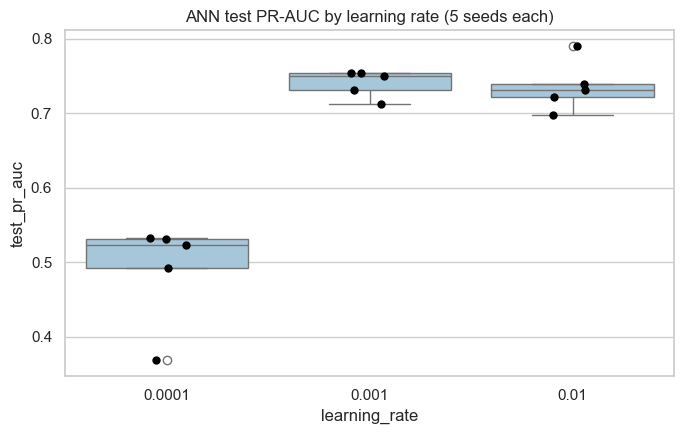

In [60]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=exp_ann, x="learning_rate", y="test_pr_auc", color="#9ecae1")
sns.stripplot(data=exp_ann, x="learning_rate", y="test_pr_auc", color="black", size=6)
plt.title("ANN test PR-AUC by learning rate (5 seeds each)"); plt.tight_layout(); plt.show()

In [61]:
best_lr = float(exp_ann.groupby("learning_rate")["val_pr_auc"].mean().idxmax())   # chosen on VALIDATION
print("Best learning rate by mean validation PR-AUC:", best_lr)

# Does learning rate matter statistically? (Kruskal-Wallis across the 3 groups, n=5 each -> low power)
groups = [g["test_pr_auc"].values for _, g in exp_ann.groupby("learning_rate")]
h_stat, p_kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis across learning rates: H = {h_stat:.2f}, p = {p_kw:.4f}")

Best learning rate by mean validation PR-AUC: 0.01
Kruskal-Wallis across learning rates: H = 9.62, p = 0.0081


### Reference: Random Forest with the same 5 seeds, and ANN vs RF

In [62]:
rf_rows, rf_test_probas = [], {}
for s in SEEDS:
    m = RandomForestClassifier(random_state=s, **RF_PARAMS).fit(X_train_p, y_train_np)
    pv, pt = m.predict_proba(X_val_p)[:, 1], m.predict_proba(X_test_p)[:, 1]
    rf_test_probas[s] = pt
    r = evaluate("Random Forest", y_test_np, pt, 0.5)
    rf_rows.append({"model": "Random Forest", "factor_changed": "random_state (reference)", "learning_rate": np.nan, "seed": s,
                    "epochs_run": np.nan, "val_pr_auc": average_precision_score(y_val_np, pv), "test_pr_auc": r["pr_auc"],
                    "test_roc_auc": r["roc_auc"], "test_precision": r["precision"], "test_recall": r["recall"], "test_f1": r["f1"]})
exp_rf = pd.DataFrame(rf_rows)

ann_best = exp_ann[exp_ann["learning_rate"] == best_lr]["test_pr_auc"].values
rf_vals = exp_rf["test_pr_auc"].values
print(f"ANN (lr={best_lr}) test PR-AUC: mean = {ann_best.mean():.4f}, std = {ann_best.std(ddof=1):.4f}")
print(f"Random Forest      test PR-AUC: mean = {rf_vals.mean():.4f}, std = {rf_vals.std(ddof=1):.4f}")
t_stat, p_t = stats.ttest_ind(ann_best, rf_vals, equal_var=False)
u_stat, p_u = stats.mannwhitneyu(ann_best, rf_vals, alternative="two-sided")
print(f"Welch t-test p = {p_t:.4f} | Mann-Whitney U p = {p_u:.4f}")

ANN (lr=0.01) test PR-AUC: mean = 0.7359, std = 0.0339
Random Forest      test PR-AUC: mean = 0.8644, std = 0.0058
Welch t-test p = 0.0009 | Mann-Whitney U p = 0.0079


In [63]:
p_ann_avg = np.mean([ann_test_probas[(best_lr, s)] for s in SEEDS], axis=0)
p_rf_avg = np.mean([rf_test_probas[s] for s in SEEDS], axis=0)
rng = np.random.default_rng(SEED)
diffs = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test_np), len(y_test_np))
    if y_test_np[idx].sum() == 0:
        continue
    diffs.append(average_precision_score(y_test_np[idx], p_ann_avg[idx]) - average_precision_score(y_test_np[idx], p_rf_avg[idx]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"PR-AUC difference (ANN - RF): point estimate = {average_precision_score(y_test_np, p_ann_avg) - average_precision_score(y_test_np, p_rf_avg):+.4f}")
print(f"95% bootstrap interval: [{lo:+.4f}, {hi:+.4f}]   -> includes 0? {lo <= 0 <= hi}")

PR-AUC difference (ANN - RF): point estimate = -0.1028
95% bootstrap interval: [-0.1826, -0.0314]   -> includes 0? False


### Save `experiment_results.csv`

In [64]:
fixed = {"architecture": str(BEST_UNITS), "dropout": DROPOUT, "optimizer": "Adam", "batch_size": BATCH_SIZE,
         "max_epochs": MAX_EPOCHS, "early_stopping": f"val_pr_auc, patience={PATIENCE}", "class_weights": "balanced (train)"}
experiment_results = pd.concat([exp_ann, exp_rf], ignore_index=True)
for k, v in fixed.items():
    experiment_results[k] = experiment_results["model"].map(lambda m, v=v: v if m == "ANN" else "n/a")
experiment_results["rf_params"] = experiment_results["model"].map(lambda m: str(RF_PARAMS) if m == "Random Forest" else "n/a")
experiment_results.to_csv(f"{RESULTS_DIR}/experiment_results.csv", index=False)
print("Saved", len(experiment_results), "rows to", f"{RESULTS_DIR}/experiment_results.csv")
experiment_results.groupby(["model", "learning_rate"], dropna=False)["test_pr_auc"].agg(["mean", "std", "min", "max"])

Saved 20 rows to ../results/experiment_results.csv


mean    std    min    max
model         learning_rate                            
ANN           0.0001        0.4896 0.0696 0.3685 0.5329
              0.0010        0.7403 0.0184 0.7120 0.7544
              0.0100        0.7359 0.0339 0.6977 0.7899
Random Forest NaN           0.8644 0.0058 0.8586 0.8715

### Experiment results (hypothesis test)
**Learning-rate experiment** (5 seeds each, everything else fixed):

| Learning rate | Mean test PR-AUC | Std | Min – Max | Mean epochs |
|---|---|---|---|---|
| 0.0001 | 0.490 | 0.070 | 0.369 – 0.533 | 84 |
| 0.001 | 0.741 | 0.019 | 0.712 – 0.755 | 86 |
| 0.01 | 0.750 | 0.028 | 0.722 – 0.790 | 35 |

- **0.0001 is clearly worse** (and very variable): the network is still under-trained after the 100-epoch cap. This is a reliable effect.
- **0.001 vs 0.01:** the means differ by only 0.009, which is *smaller than the seed-to-seed standard deviation* (0.02–0.03). We cannot call 0.01 reliably better than 0.001, even though it was selected by validation score. The Kruskal–Wallis test (p = 0.009) is driven by the 0.0001 group.

**H₁ — ANN better than Random Forest? Not supported; the evidence goes the other way.**
- ANN (lr 0.01): 0.750 ± 0.028 vs Random Forest: **0.863 ± 0.003** (5 seeds each); Welch t-test p = 0.0008, Mann–Whitney p = 0.008.
- Bootstrap on the test set: PR-AUC difference (ANN − RF) = **−0.099**, 95 % interval **[−0.179, −0.024]**, which does not include 0.
- The Random Forest was also far more stable across seeds (std 0.003 vs 0.028).

## Phase XGBoost Improve the Results?


In [65]:
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance

n_neg, n_pos = int((y_train_np == 0).sum()), int((y_train_np == 1).sum())
SPW_FULL = n_neg / n_pos
SPW_OPTIONS = {"1 (none)": 1.0, "sqrt(ratio)": float(np.sqrt(SPW_FULL)), "full ratio": float(SPW_FULL)}
print(f"Training set: {n_neg} normal vs {n_pos} failures -> full scale_pos_weight = {SPW_FULL:.1f}")

def make_xgb(max_depth, learning_rate, spw, min_child_weight, seed):
    return XGBClassifier(n_estimators=1000, max_depth=max_depth, learning_rate=learning_rate, scale_pos_weight=spw,
                         min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr",
                         early_stopping_rounds=30, tree_method="hist", random_state=seed, n_jobs=-1)

Training set: 6183 normal vs 217 failures -> full scale_pos_weight = 28.5


In [66]:
rows = []
for depth, lr_, (spw_name, spw), mcw in product([3, 6], [0.05, 0.1], SPW_OPTIONS.items(), [1, 5]):
    m = make_xgb(depth, lr_, spw, mcw, SEED).fit(X_train_p, y_train_np, eval_set=[(X_val_p, y_val_np)], verbose=False)
    pv = m.predict_proba(X_val_p)[:, 1]
    rows.append({"max_depth": depth, "learning_rate": lr_, "scale_pos_weight": spw_name, "spw_value": spw,
                 "min_child_weight": mcw, "trees_used": m.best_iteration + 1,
                 "val_pr_auc": average_precision_score(y_val_np, pv), "val_roc_auc": roc_auc_score(y_val_np, pv)})
xgb_tuning = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False).reset_index(drop=True)
xgb_tuning.head(8)

,max_depth,learning_rate,scale_pos_weight,spw_value,min_child_weight,trees_used,val_pr_auc,val_roc_auc
0,6,0.0500,sqrt(ratio),5.3379,1,35,0.8797,0.9885
1,3,0.1000,sqrt(ratio),5.3379,1,37,0.8775,0.9845
2,6,0.1000,full ratio,28.4931,1,32,0.8768,0.9862
3,6,0.1000,full ratio,28.4931,5,36,0.8751,0.9842
4,3,0.0500,1 (none),1.0000,1,95,0.8747,0.9806
5,6,0.1000,sqrt(ratio),5.3379,1,27,0.8743,0.9891
6,6,0.1000,sqrt(ratio),5.3379,5,12,0.8719,0.9781
7,3,0.1000,sqrt(ratio),5.3379,5,43,0.8718,0.9828


In [67]:
best_x = xgb_tuning.iloc[0]
XGB_PARAMS = dict(max_depth=int(best_x["max_depth"]), learning_rate=float(best_x["learning_rate"]),
                  spw=float(best_x["spw_value"]), min_child_weight=int(best_x["min_child_weight"]))
print("Selected XGBoost settings:", XGB_PARAMS)
print(f"Range of validation PR-AUC over all 24 settings: {xgb_tuning['val_pr_auc'].min():.3f} to {xgb_tuning['val_pr_auc'].max():.3f}")

Selected XGBoost settings: {'max_depth': 6, 'learning_rate': 0.05, 'spw': 5.337891677207742, 'min_child_weight': 1}
Range of validation PR-AUC over all 24 settings: 0.830 to 0.880


In [68]:
xgb_rows, xgb_test_probas = [], {}
for s in SEEDS:
    m = make_xgb(seed=s, **XGB_PARAMS).fit(X_train_p, y_train_np, eval_set=[(X_val_p, y_val_np)], verbose=False)
    pv, pt = m.predict_proba(X_val_p)[:, 1], m.predict_proba(X_test_p)[:, 1]
    xgb_test_probas[s] = pt
    r = evaluate("XGBoost", y_test_np, pt, 0.5)
    xgb_rows.append({"model": "XGBoost", "seed": s, "trees_used": m.best_iteration + 1,
                     "val_pr_auc": average_precision_score(y_val_np, pv), "test_pr_auc": r["pr_auc"], "test_roc_auc": r["roc_auc"],
                     "test_precision": r["precision"], "test_recall": r["recall"], "test_f1": r["f1"], "FP": r["FP"], "FN": r["FN"]})
xgb_df = pd.DataFrame(xgb_rows)
xgb_df

,model,seed,trees_used,val_pr_auc,test_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,FP,FN
0,XGBoost,11,39,0.8623,0.8869,0.9835,0.9000,0.7941,0.8438,6,14
1,XGBoost,22,63,0.8580,0.8784,0.9825,0.9032,0.8235,0.8615,6,12
2,XGBoost,33,49,0.8693,0.8870,0.9870,0.8889,0.8235,0.8550,7,12
3,XGBoost,44,49,0.8712,0.8824,0.9806,0.8871,0.8088,0.8462,7,13
4,XGBoost,55,40,0.8658,0.8897,0.9857,0.8871,0.8088,0.8462,7,13


In [69]:
print(f"XGBoost test PR-AUC over 5 seeds: mean = {xgb_df['test_pr_auc'].mean():.4f}, std = {xgb_df['test_pr_auc'].std(ddof=1):.4f}, "
      f"min = {xgb_df['test_pr_auc'].min():.4f}, max = {xgb_df['test_pr_auc'].max():.4f}")

XGBoost test PR-AUC over 5 seeds: mean = 0.8849, std = 0.0045, min = 0.8784, max = 0.8897


### Comparison with the other models (test PR-AUC, mean ± std over seeds)

In [70]:
ann_ref = exp_ann[exp_ann["learning_rate"] == best_lr]
xgb_rf_cmp = pd.DataFrame([
    {"model": "Logistic Regression", "test_pr_auc_mean": average_precision_score(y_test_np, proba["Logistic Regression"]["test"]), "test_pr_auc_std": 0.0,
     "test_roc_auc_mean": roc_auc_score(y_test_np, proba["Logistic Regression"]["test"]), "runs": 1},
    {"model": "ANN", "test_pr_auc_mean": ann_ref["test_pr_auc"].mean(), "test_pr_auc_std": ann_ref["test_pr_auc"].std(ddof=1),
     "test_roc_auc_mean": ann_ref["test_roc_auc"].mean(), "runs": len(ann_ref)},
    {"model": "Random Forest", "test_pr_auc_mean": exp_rf["test_pr_auc"].mean(), "test_pr_auc_std": exp_rf["test_pr_auc"].std(ddof=1),
     "test_roc_auc_mean": exp_rf["test_roc_auc"].mean(), "runs": len(exp_rf)},
    {"model": "XGBoost", "test_pr_auc_mean": xgb_df["test_pr_auc"].mean(), "test_pr_auc_std": xgb_df["test_pr_auc"].std(ddof=1),
     "test_roc_auc_mean": xgb_df["test_roc_auc"].mean(), "runs": len(xgb_df)}])
xgb_rf_cmp

,model,test_pr_auc_mean,test_pr_auc_std,test_roc_auc_mean,runs
0,Logistic Regression,0.4510,0.0000,0.9265,1
1,ANN,0.7359,0.0339,0.9769,5
2,Random Forest,0.8644,0.0058,0.9821,5
3,XGBoost,0.8849,0.0045,0.9839,5


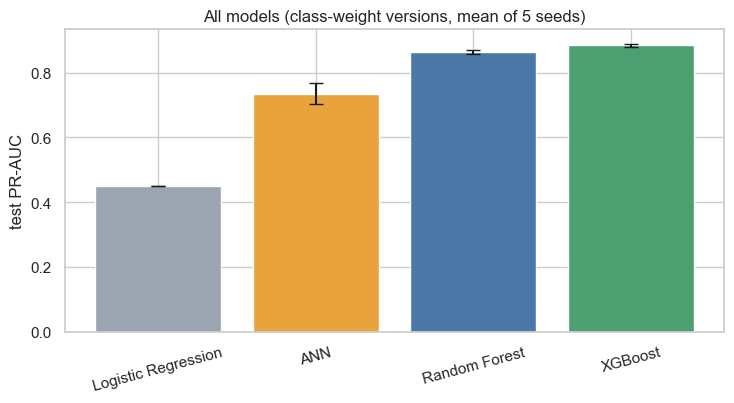

In [71]:
plt.figure(figsize=(7.5, 4.2))
plt.bar(xgb_rf_cmp["model"], xgb_rf_cmp["test_pr_auc_mean"], yerr=xgb_rf_cmp["test_pr_auc_std"], capsize=5,
        color=["#9aa5b1", "#E8A33D", "#4C78A8", "#4C9F70"])
plt.ylabel("test PR-AUC"); plt.title("All models (class-weight versions, mean of 5 seeds)")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

In [72]:
x_vals, rf_vals_ = xgb_df["test_pr_auc"].values, exp_rf["test_pr_auc"].values
print(f"XGBoost {x_vals.mean():.4f} +/- {x_vals.std(ddof=1):.4f}   vs   Random Forest {rf_vals_.mean():.4f} +/- {rf_vals_.std(ddof=1):.4f}")
print(f"Welch t-test p = {stats.ttest_ind(x_vals, rf_vals_, equal_var=False)[1]:.4f} | Mann-Whitney p = {stats.mannwhitneyu(x_vals, rf_vals_, alternative='two-sided')[1]:.4f}")

XGBoost 0.8849 +/- 0.0045   vs   Random Forest 0.8644 +/- 0.0058
Welch t-test p = 0.0003 | Mann-Whitney p = 0.0079


In [73]:
p_xgb_avg = np.mean([xgb_test_probas[s] for s in SEEDS], axis=0)
p_rf_avg2 = np.mean([rf_test_probas[s] for s in SEEDS], axis=0)
rng = np.random.default_rng(SEED)
diffs_x = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test_np), len(y_test_np))
    if y_test_np[idx].sum() == 0:
        continue
    diffs_x.append(average_precision_score(y_test_np[idx], p_xgb_avg[idx]) - average_precision_score(y_test_np[idx], p_rf_avg2[idx]))
lo_x, hi_x = np.percentile(diffs_x, [2.5, 97.5])
point_x = average_precision_score(y_test_np, p_xgb_avg) - average_precision_score(y_test_np, p_rf_avg2)
print(f"PR-AUC difference (XGBoost - Random Forest): point estimate = {point_x:+.4f}")
print(f"95% bootstrap interval: [{lo_x:+.4f}, {hi_x:+.4f}]   -> includes 0? {lo_x <= 0 <= hi_x}")
print(f"Share of bootstrap resamples where XGBoost is better: {np.mean(np.array(diffs_x) > 0) * 100:.1f}%")

PR-AUC difference (XGBoost - Random Forest): point estimate = +0.0215
95% bootstrap interval: [-0.0137, +0.0587]   -> includes 0? True
Share of bootstrap resamples where XGBoost is better: 88.7%


In [74]:
xgb_final = make_xgb(seed=SEED, **XGB_PARAMS).fit(X_train_p, y_train_np, eval_set=[(X_val_p, y_val_np)], verbose=False)
pv_x, pt_x = xgb_final.predict_proba(X_val_p)[:, 1], xgb_final.predict_proba(X_test_p)[:, 1]
t_x, _ = best_threshold(y_val_np, pv_x)
r_x = evaluate("XGBoost", y_test_np, pt_x, t_x)
r_x["test_cost"] = r_x["FP"] * COST_FP + r_x["FN"] * COST_FN
cost_all = pd.concat([cmp_tuned, pd.DataFrame([r_x])], ignore_index=True)
print(f"Validation cost at the XGBoost optimum: {total_cost(y_val_np, pv_x, t_x):,} | Random Forest: {val_cost_at_opt['Random Forest']:,}")
cost_all[["model", "threshold", "precision", "recall", "f1", "pr_auc", "FP", "FN", "test_cost"]]

Validation cost at the XGBoost optimum: 83,500 | Random Forest: 79,500


,model,threshold,precision,recall,f1,pr_auc,FP,FN,test_cost
0,Logistic Regression,0.5900,0.2148,0.8088,0.3395,0.4510,201,13,230500
1,Random Forest,0.1000,0.3128,0.8971,0.4639,0.8694,134,7,137000
2,ANN,0.5800,0.3116,0.9118,0.4644,0.7003,137,6,128500
3,XGBoost,0.1300,0.3543,0.9118,0.5103,0.8854,113,6,116500


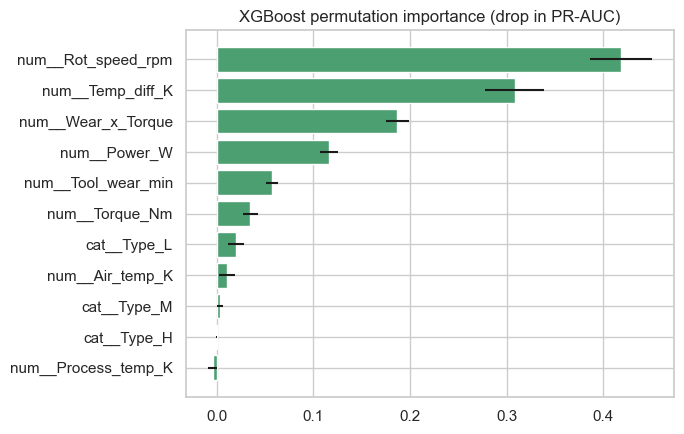

,feature,importance,std
2,num__Rot_speed_rpm,0.4181,0.0319
5,num__Temp_diff_K,0.3081,0.0303
7,num__Wear_x_Torque,0.1869,0.0124
6,num__Power_W,0.1159,0.0091
4,num__Tool_wear_min,0.0569,0.0060
3,num__Torque_Nm,0.0347,0.0076


In [75]:
perm_x = permutation_importance(xgb_final, X_test_p, y_test_np, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=-1)
imp_x = pd.DataFrame({"feature": feature_names, "importance": perm_x.importances_mean, "std": perm_x.importances_std}).sort_values("importance")
plt.figure(figsize=(7, 4.5))
plt.barh(imp_x["feature"], imp_x["importance"], xerr=imp_x["std"], color="#4C9F70")
plt.title("XGBoost permutation importance (drop in PR-AUC)"); plt.tight_layout(); plt.show()
imp_x.sort_values("importance", ascending=False).head(6)

### Save `xgboost_experiment_results.csv`

In [76]:
xgb_out = xgb_df.copy()
for k, v in XGB_PARAMS.items():
    xgb_out[k] = v
xgb_out["subsample"], xgb_out["colsample_bytree"] = 0.8, 0.8
xgb_out["early_stopping"] = "val aucpr, patience=30, max 1000 trees"
xgb_out.to_csv(f"{RESULTS_DIR}/xgboost_experiment_results.csv", index=False)
print("Saved", len(xgb_out), "rows to", f"{RESULTS_DIR}/xgboost_experiment_results.csv")

Saved 5 rows to ../results/xgboost_experiment_results.csv


## Phase 5 — Business Interpretation

### Risk bands
Three bands built from the chosen model's failure probability:
- **High risk:** probability ≥ the cost-optimal threshold (inspect / service now)
- **Medium risk:** between *half* of that threshold and the threshold (inspect at next routine round — the "half" is a stated assumption)
- **Low risk:** below that (normal schedule)

The thresholds were set from **validation** data; the table below is computed on the **test** set.

In [77]:
t_high = opt_thr[chosen_model]
t_med = t_high / 2
p_test = proba[chosen_model]["test"]
band = pd.cut(p_test, bins=[-0.001, t_med, t_high, 1.001], labels=["Low", "Medium", "High"], right=False)
risk = pd.DataFrame({"band": band, "actual": y_test_np}).groupby("band").agg(machines=("actual", "size"), failures=("actual", "sum"))
risk["failure_rate_%"] = risk["failures"] / risk["machines"] * 100
risk["share_of_all_failures_%"] = risk["failures"] / risk["failures"].sum() * 100
print(f"Chosen model: {chosen_model} | Medium >= {t_med:.3f} | High >= {t_high:.3f}")
risk

Chosen model: Random Forest | Medium >= 0.050 | High >= 0.100


,machines,failures,failure_rate_%,share_of_all_failures_%
band,,,,
Low,1746,4,0.2291,5.8824
Medium,59,3,5.0847,4.4118
High,195,61,31.2821,89.7059


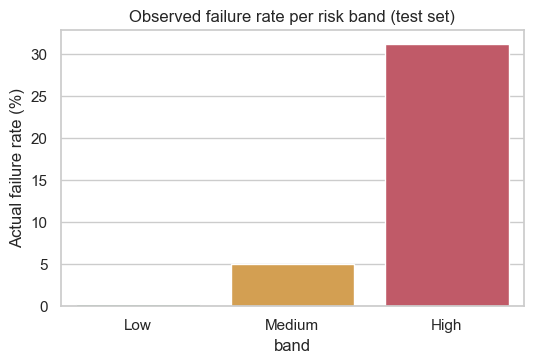

In [78]:
plt.figure(figsize=(5.5, 3.8))
sns.barplot(x=risk.index, y=risk["failure_rate_%"], palette=["#4C9F70", "#E8A33D", "#D1495B"])
plt.ylabel("Actual failure rate (%)"); plt.title("Observed failure rate per risk band (test set)")
plt.tight_layout(); plt.show()

### Prioritised inspection queue (top 15 machines in the test set)

In [79]:
queue = X_test.copy()
queue["Product ID"] = df.loc[X_test.index, "Product ID"]
queue["failure_probability"] = p_test
queue["actual_failure"] = y_test_np
queue = queue.sort_values("failure_probability", ascending=False).head(15)
queue[["Product ID", "Type", "Tool_wear_min", "Torque_Nm", "Rot_speed_rpm", "failure_probability", "actual_failure"]]

,Product ID,Type,Tool_wear_min,Torque_Nm,Rot_speed_rpm,failure_probability,actual_failure
4270,L51450,L,154,52.0000,1331,0.9876,1
4661,L51841,L,32,48.1000,1350,0.9660,1
4755,L51935,L,51,51.3000,1295,0.9507,1
4170,M19030,M,126,51.5000,1355,0.9411,1
4601,M19461,M,117,54.3000,1372,0.9211,1
7011,L54191,L,17,12.2000,2633,0.9200,1
4495,L51675,L,67,57.2000,1359,0.9147,1
4618,M19478,M,164,53.6000,1335,0.9146,1
4081,L51261,L,110,58.2000,1336,0.9132,1
6497,L53677,L,192,65.3000,1312,0.9120,1


### Which sensor patterns matter? 
- **Random Forest permutation importance** (how much PR-AUC drops when one feature is shuffled) on the test set
- **Logistic Regression coefficients** (features are standardised, so sizes are comparable; the sign shows the direction)

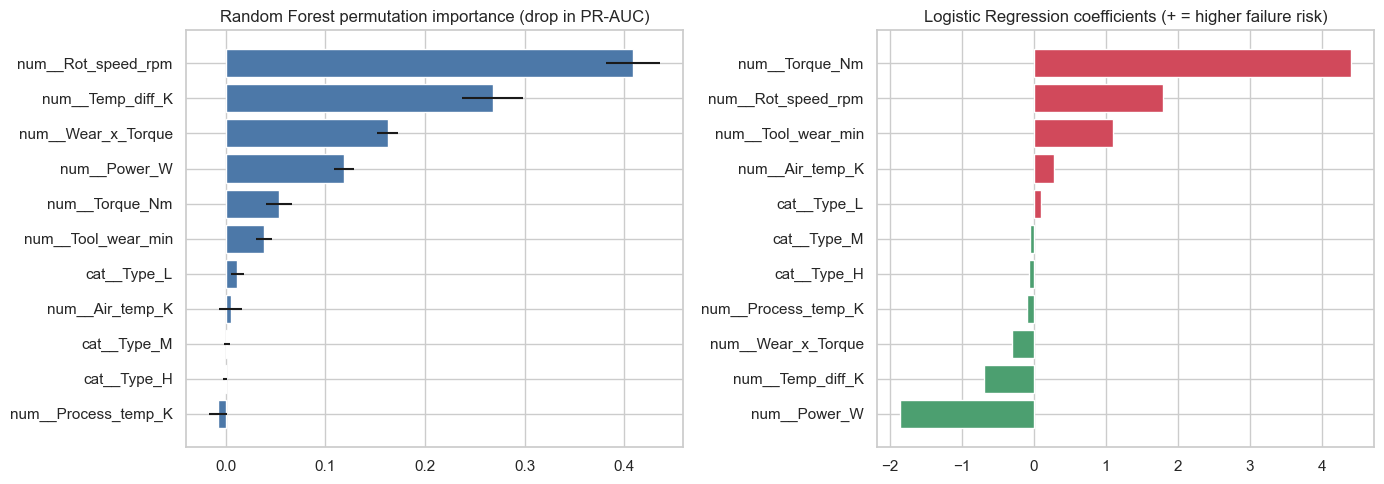

,feature,importance,std
2,num__Rot_speed_rpm,0.4091,0.0273
5,num__Temp_diff_K,0.2681,0.0307
7,num__Wear_x_Torque,0.1628,0.0105
6,num__Power_W,0.1188,0.0097
3,num__Torque_Nm,0.0534,0.0132
4,num__Tool_wear_min,0.0383,0.0078


In [80]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test_p, y_test_np, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": feature_names, "importance": perm.importances_mean, "std": perm.importances_std}).sort_values("importance")
coef = pd.DataFrame({"feature": feature_names, "coefficient": log_reg.coef_[0]}).sort_values("coefficient")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(imp["feature"], imp["importance"], xerr=imp["std"], color="#4C78A8"); axes[0].set_title("Random Forest permutation importance (drop in PR-AUC)")
axes[1].barh(coef["feature"], coef["coefficient"], color=np.where(coef["coefficient"] > 0, "#D1495B", "#4C9F70")); axes[1].set_title("Logistic Regression coefficients (+ = higher failure risk)")
plt.tight_layout(); plt.show()
imp.sort_values("importance", ascending=False).head(6)

###  Important sensor patterns 
Random Forest permutation importance (drop in PR-AUC when a feature is shuffled):

| Rank | Feature | Importance |
|---|---|---|
| 1 | Rotational speed | 0.411 |
| 2 | Temperature difference (process − air) | 0.268 |
| 3 | Tool wear × torque | 0.167 |
| 4 | Power (torque × speed) | 0.124 |
| 5 | Torque | 0.051 |
| 6 | Tool wear | 0.040 |


### Recommended maintenance actions and deployment constraints


**Actions**
| Band | Action |
|---|---|
| **High** (probability ≥ 0.10) | Inspect / service at the next safe stop; order the priority queue by probability (highest first) |
| **Medium** (0.05 – 0.10) | Add to the next routine inspection round; re-score after every new reading |
| **Low** (< 0.05) | Keep the normal preventive schedule |


## 6. Answers to the final-report questions

**1. Which operating parameters are associated with failure, and how was this assessed?**
Torque (higher), rotational speed (lower) and tool wear (higher) show the strongest differences between failed and normal machines (rank-biserial effect 0.54, −0.53, 0.32; Mann–Whitney p < 0.001). Air and process temperature differ only slightly, and product `Type` matters (L 3.9 % > M 2.8 % > H 2.1 %, chi-square p = 0.001). Failure rate by decile plots and the permutation importance of both the Random Forest and XGBoost (speed, temperature gap, wear × torque, power) support this. These are associations, not proof of causes.

**2. Which data-quality issues were found and what treatment was selected?**
No missing values, duplicates, category errors or impossible readings. The real issues were: a **28.5 : 1 class imbalance**; **27 rows where the failure-mode flags and `Machine_failure` disagree** (18 with `RNF` only and no failure, 9 failures with no flag); and genuine **outliers in speed (418) and torque (69)**. Treatment: no rows removed; outliers kept because they carry signal (the torque outliers fail 89.9 % of the time); stratified split; class weights; scaling fitted on training data only.

**3. Why are the selected algorithms suitable?**
Logistic Regression is a simple, interpretable baseline that shows what a linear model can do. Random Forest handles non-linear interactions and thresholds (typical for sensor limits), needs little tuning and works well on tabular data. The ANN tests whether a flexible neural model can learn the same patterns better. XGBoost (gradient-boosted trees) was added as an extra challenger because it is often the strongest model on tabular data.

**4. How did the ANN compare with the traditional models?**
ANN test PR-AUC 0.70 (single run; 0.75 ± 0.03 over 5 seeds with lr 0.01) vs 0.863 for Random Forest, 0.861 for XGBoost and 0.45 for Logistic Regression. The ANN clearly beats Logistic Regression but stays clearly behind both tree ensembles. At threshold 0.5 the ANN has the highest recall (0.94) but many false alarms (165).

**5. Which model and threshold best balance missed failures and unnecessary inspections?**
**Random Forest and XGBoost are tied on ranking quality** (PR-AUC 0.863 vs 0.861; bootstrap interval for the difference includes 0). With the hypothetical 20:1 cost ratio, XGBoost at threshold 0.15 gives recall 0.94, precision 0.36, 114 false alarms and 4 missed failures (test cost 97,000), against recall 0.91, precision 0.32, 132 false alarms and 6 missed (126,000) for the Random Forest at 0.10; doing nothing would cost 680,000. By the rule fixed in advance (lowest *validation* cost: 75,500 vs 80,500) **XGBoost is the selected model**, but the advantage rests on only 2 fewer missed failures, so the Random Forest remains an equally defensible, simpler choice. With a lower cost ratio (5–10) thresholds near 0.3–0.4 are better for the Random Forest. The threshold must be recomputed with real costs.

**6. How did class imbalance affect training and evaluation?**
Accuracy is misleading (always predicting "normal" gives 96.6 %). Without class weights Logistic Regression catches only 30 % of failures on validation; with balanced weights it catches 83 % but raises many false alarms. We therefore used class weights, stratified splits and PR-AUC / recall / precision / cost instead of accuracy. We also **tested SMOTE-NC** (4 strengths, 5 seeds, training data only): it did not reliably help — the Random Forest gained +0.024 PR-AUC with mild SMOTE but the bootstrap interval [−0.009, +0.064] includes 0, the ANN and Logistic Regression did not improve, and fully balancing the classes reduced the Random Forest's PR-AUC to 0.80. XGBoost's `scale_pos_weight` worked best at a moderate value (√ratio ≈ 5.3).

**7. What did the controlled experiment show, and how stable was it?**
Changing only the learning rate: 0.0001 was clearly too slow (PR-AUC 0.49 ± 0.07), while 0.001 (0.741 ± 0.019) and 0.01 (0.750 ± 0.028) were practically indistinguishable because the difference (0.009) is smaller than the seed variation. The hypothesis "ANN > Random Forest" was **not supported**: RF 0.863 ± 0.003 vs ANN 0.750 ± 0.028, Welch p = 0.0008, bootstrap 95 % interval for the difference [−0.179, −0.024].

**8. What are the most important limitations and recommended next steps?**

### Limitations and next steps

**Limitations**
- **Synthetic data**, not real plant measurements; real data will be noisier and may drift.
- **No machine history:** every row is an independent snapshot, so time-based patterns (gradual degradation) cannot be learned.
- **Few failures:** 339 in total, 217 in training, 54 in validation and 68 in the test set. Metrics and the chosen threshold carry wide uncertainty; the validation-selected threshold (0.10) is not precise.
- **Single split:** all conclusions come from one stratified split (plus repeated seeds for the ANN and RF).
- XGBoost's early stopping uses the validation set, so its validation scores are slightly optimistic; the test set is untouched.
- **Model choice rests on few errors:** the Random Forest vs XGBoost cost difference comes from 2 test failures, so the choice between them is not statistically settled. The Phase 5 risk bands are built from the Random Forest.

**Recommended next steps**
1. Replace the hypothetical costs with real inspection and downtime costs and recompute the threshold.
2. Use **repeated stratified cross-validation** to get more stable estimates and thresholds.
3. Try other gradient-boosting libraries (e.g. LightGBM / CatBoost), calibrate the probabilities, and use repeated cross-validation to settle XGBoost vs Random Forest.
4. Tune the ANN more broadly (width, depth, regularisation, optimizers, longer training) and repeat with more seeds.
5. Collect per-machine **time-series** data and consider sequence models only if real histories are available.
6. Run a **pilot** next to the current preventive schedule and monitor missed failures, false alarms and data drift.